# Training ME5S for Multi-Label Safety Classification

Each Aegis prompt receives three targets:

- **Unsafe** $y_u \in \{0, 1\}$, from `prompt_label`, on every prompt.
- **Needs caution** $y_c \in \{0, 1\}$, on safe prompts only: whether `Needs Caution` appears in `violated_categories`. It is ignored on unsafe prompts, where it is a minority annotator vote.
- **Categories** $\mathbf{y}_{\text{cat}} \in \{0, 1\}^{C}$, on unsafe prompts only: the unsafe categories in `violated_categories`, after folding `Manipulation`, `Immoral/Unethical` and `Illegal Activity` into `Other` ($C = 19$). Categories listed on safe prompts are minority votes and are ignored, though the prompts themselves are kept.

`APPROACH` selects one of two heads on the shared LoRA-adapted encoder:

- **Flat:** one feed-forward network with $2 + C$ outputs. The masked-out targets are set to zero, so its outputs learn joint probabilities $p(y_u = 0, y_c = 1 \mid x)$ and $p(y_u = 1, y_{\text{cat},k} = 1 \mid x)$.
- **Hierarchical:** three feed-forward networks with $1$, $1$ and $C$ outputs, trained jointly. The caution loss is masked to safe prompts and the category loss to unsafe prompts, so the second and third heads learn conditionals $p(y_c = 1 \mid y_u = 0, x)$ and $p(y_{\text{cat},k} = 1 \mid y_u = 1, x)$.

Both are evaluated on conditionals, the flat outputs being divided by the branch probability, and on gated end-to-end decisions: a prompt predicted unsafe reports its categories, and a prompt predicted safe reports needs caution or not. Categories span three orders of magnitude in frequency, so each output's positive class is weighted by its negative-to-positive ratio, clipped at `POS_WEIGHT_MAX`, and categories are also ranked by threshold-free average precision.

The data are the cleaned Aegis splits produced by `clean_aegis_splits`, shared with `training_binary_classifier.ipynb`: deduplicated, free of `REDACTED` prompts, label conflicts and cross-split leakage, and limited to `MAX_LEN` tokens.

In [1]:
from __future__ import annotations

import json
import math
import os
import random
import shutil
from collections import Counter, OrderedDict
from enum import StrEnum
from pathlib import Path
from typing import Any, Literal, NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# In-notebook rendering of the per-epoch attention heatmaps.
from IPython.display import HTML, display

from datasets import Dataset as HFDataset
from datasets import DatasetDict
from datasets import load_dataset
from peft import LoraConfig, TaskType, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict
from peft.utils import load_peft_weights
from torch import Tensor
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup

# ---------------------------------------------------------------------------
# Constants
# ---------------------------------------------------------------------------

# Head architecture: one flat FFN with 2 + C outputs, or three FFNs (unsafe,
# needs caution, categories) trained jointly with masked losses.
APPROACH: Literal["flat", "hierarchical"] = "hierarchical"

# ME5-small: 12-layer BERT encoder, hidden_dim=384, distilled from XLM-R
MODEL_ID = "intfloat/multilingual-e5-small"
HIDDEN_DIM = 384
MAX_LEN = 128

# Safety dataset
DATASET_ID = "nvidia/Aegis-AI-Content-Safety-Dataset-2.0"

# Records kept from each cleaned split (see clean_aegis_splits); None keeps all of
# them, which preserves every example of the rare categories.
SUBSET_SIZE: int | None = None
VAL_SIZE: int | None = None
TEST_SIZE: int | None = None

# Label space. Categories with fewer than ~15 training prompts, and no more than one
# test prompt, are folded into "Other"; "Needs Caution" is a separate target.
NEEDS_CAUTION = "Needs Caution"
CATEGORY_FOLDS = {
    "Manipulation": "Other",
    "Immoral/Unethical": "Other",
    "Illegal Activity": "Other",
}

# Class-imbalance handling: each output's positive class is weighted by its
# negative-to-positive ratio in the training split, clipped at POS_WEIGHT_MAX so
# the rarest categories cannot dominate the loss.
POS_WEIGHT_MAX = 50.0

# Weights of the three masked losses of the hierarchical approach.
LOSS_WEIGHTS = {"unsafe": 1.0, "caution": 1.0, "categories": 1.0}

# Decision thresholds on p(unsafe | x), p(caution | safe, x), and p(c | unsafe, x).
UNSAFE_THRESHOLD = 0.5
CAUTION_THRESHOLD = 0.5
CATEGORY_THRESHOLD = 0.5

# Per-category test metrics with fewer positive test prompts than this are flagged.
LOW_SUPPORT = 10

BATCH_SIZE = 64

GRAD_CLIP_NORM = 1.0

WARMUP_RATIO = 0.05

NUM_EPOCHS = 100
LOG_EVERY = 25

VISUALIZE_EVERY = 10

# Fixed records tracked by the per-epoch diagnostics: half from train, half from
# validation, each half split evenly between surely-safe, needs-caution, and unsafe.
NUM_REPRESENTATIVE = 12

# Category panel of the diagnostics: ground-truth categories plus the top-k predicted.
CATEGORY_PANEL_TOP_K = 5

# LoRA adapters on the attention projections of every encoder layer. PEFT matches
# target entries by module-name suffix, so "attention.output.dense" targets only
# the attention O-projection and never the FFN's separate "output.dense" module.
LORA_RANK = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LORA_TARGET_MODULES = ["query", "key", "value", "attention.output.dense"]

# Feed-forward classification heads (every head of the hierarchical approach uses
# the same architecture).
HEAD_NUM_LAYERS = 3
HEAD_HIDDEN_DIM = 256
HEAD_WEIGHT_INIT = "x_normal"

# Checkpointing: the resumable training state is written every CHECKPOINT_EVERY
# epochs (and after the final epoch), overwriting the previous one. The model with
# the lowest validation loss is exported to RUN_DIR / "best" whenever it improves.
OUTPUT_DIR = Path("../outputs/multi_label")
RUN_NAME = f"me5s_lora_{APPROACH}"
RESUME = False
CHECKPOINT_EVERY = 10

SEED = 0


def seed_everything(seed: int) -> None:
    """
    Seed the Python, NumPy, and PyTorch (CPU and CUDA) random number generators.

    :param seed:    Seed shared by every generator.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything(SEED)

In [2]:
class AegisLabels(StrEnum):
    SAFE = "safe"
    UNSAFE = "unsafe"


class AegisKeys(StrEnum):
    PROMPT = "prompt"
    RESPONSE = "response"
    PROMPT_LABEL = "prompt_label"
    RESPONSE_LABEL = "response_label"
    VIOLATED_CATEGORIES = "violated_categories"
    PROMPT_LABEL_SOURCE = "prompt_label_source"

In [3]:
def average_pool(last_hidden_states: Tensor, non_padding_mask: Tensor) -> Tensor:
    """
    Mean-pool token hidden states over non-padded positions.

    :param last_hidden_states:  Shape ``(B, L, D)`` — one vector per token position.
    :param non_padding_mask:    Shape ``(B, L)`` — 1 for real tokens, 0 for padding.
    :return:                    Shape ``(B, D)`` — one dense embedding per input sequence.
    """
    # [B, L, D] — zero out padded positions so they do not contribute to the sum.
    b, l, d = last_hidden_states.shape
    last_hidden = last_hidden_states.masked_fill(~non_padding_mask.reshape(b, l, 1).bool(), 0.0)

    # [B, D] — divide the summed vectors by the count of real tokens per sequence.
    return last_hidden.sum(dim=1) / non_padding_mask.sum(dim=1).reshape(b, 1)

In [4]:
# Aegis stores prompts that could not be released verbatim as this placeholder.
REDACTED_PROMPT = "REDACTED"

# Official splits in leakage-removal order: a prompt that occurs in several splits
# is kept only in the last of them, so no evaluation prompt is seen in training.
AEGIS_SPLITS = ("train", "validation", "test")


def parse_categories(raw: str | None) -> list[str]:
    """
    Split an Aegis ``violated_categories`` string into category names.

    :param raw: Comma-separated categories; ``None`` or empty means none.
    :return:    Stripped category names in their original order.
    """
    return [category.strip() for category in (raw or "").split(",") if category.strip()]


def clean_aegis_splits(
    dataset_dict: DatasetDict,
    tokenizer: Any,
    max_length: int,
) -> dict[str, HFDataset]:
    """
    Build deduplicated, leakage-free prompt splits that fit the token budget.

    Aegis pairs one prompt with several responses, so a prompt can repeat within a
    split and across splits. Each split is cleaned in five steps:

    1. Drop ``REDACTED`` placeholder prompts, whose text cannot support any label.
    2. Drop prompts longer than ``max_length`` tokens (special tokens included), so
       the collate function never truncates.
    3. Merge repeated prompts into one record whose categories are the union over
       the repeats in first-seen order; ``violated_categories`` is already a union
       over annotators, so the union keeps its meaning.
    4. Drop prompts whose repeats disagree on ``prompt_label``.
    5. Drop prompts that also occur in a later split (train, validation, test).

    :param dataset_dict:    The Aegis splits ``train``, ``validation``, and ``test``.
    :param tokenizer:       A HuggingFace ``PreTrainedTokenizer``.
    :param max_length:      Maximum allowed token length (inclusive).
    :return:                Split name to a dataset with ``prompt``, ``prompt_label``,
                            and ``violated_categories`` columns, in first-seen order.
    """
    prompt_key = AegisKeys.PROMPT.value
    label_key = AegisKeys.PROMPT_LABEL.value
    categories_key = AegisKeys.VIOLATED_CATEGORIES.value

    # Steps 1-3: group each split's in-budget, non-redacted records by exact prompt,
    # collecting every label seen and the union of categories.
    grouped: dict[str, dict[str, tuple[set[str], list[str]]]] = {}
    raw_sizes: dict[str, int] = {}
    for split in AEGIS_SPLITS:
        dataset = dataset_dict[split]
        prompts = list(dataset[prompt_key])
        labels = list(dataset[label_key])
        raw_categories = list(dataset[categories_key])
        input_ids = tokenizer(prompts, truncation=False, verbose=False)["input_ids"]
        raw_sizes[split] = len(prompts)

        groups: dict[str, tuple[set[str], list[str]]] = {}
        for prompt, label, raw, ids in zip(prompts, labels, raw_categories, input_ids, strict=True):
            if len(ids) > max_length or prompt.strip().upper() == REDACTED_PROMPT:
                continue
            seen_labels, merged = groups.setdefault(prompt, (set(), []))
            seen_labels.add(label)
            for category in parse_categories(raw):
                if category not in merged:
                    merged.append(category)
        grouped[split] = groups

    # Steps 4-5: drop label conflicts and prompts that reappear in a later split.
    cleaned: dict[str, HFDataset] = {}
    print(f"{'split':<12}{'records':>9}{'unique fit':>12}{'conflicts':>11}{'leaked':>8}{'kept':>8}")
    for position, split in enumerate(AEGIS_SPLITS):
        later_prompts: set[str] = set().union(*(grouped[s] for s in AEGIS_SPLITS[position + 1:]))
        records: dict[str, list[str]] = {prompt_key: [], label_key: [], categories_key: []}
        num_conflicts = 0
        num_leaked = 0
        for prompt, (seen_labels, merged) in grouped[split].items():
            if len(seen_labels) > 1:
                num_conflicts += 1
                continue
            if prompt in later_prompts:
                num_leaked += 1
                continue
            records[prompt_key].append(prompt)
            records[label_key].append(next(iter(seen_labels)))
            records[categories_key].append(", ".join(merged))
        cleaned[split] = HFDataset.from_dict(records)
        print(
            f"{split:<12}{raw_sizes[split]:>9}{len(grouped[split]):>12}{num_conflicts:>11}"
            f"{num_leaked:>8}{len(cleaned[split]):>8}"
        )
    return cleaned


def take_leading(dataset: HFDataset, size: int | None) -> HFDataset:
    """
    Keep the first ``size`` records of a cleaned split, or all of them for ``None``.

    :param dataset: A split returned by :func:`clean_aegis_splits`.
    :param size:    Number of records to keep; ``None`` keeps every record.
    :return:        The leading records, in their original order.
    """
    if size is None:
        return dataset
    if size > len(dataset):
        print(f"Warning: only {len(dataset)} cleaned records available; requested {size}.")
    return dataset.select(range(min(size, len(dataset))))

In [5]:
class MultiLabelTargets(NamedTuple):
    """
    Targets of a batch of prompts.

    :param unsafe:      1.0 for unsafe prompts, ``[B]``.
    :param caution:     1.0 for safe prompts flagged ``Needs Caution``; always 0.0 on
                        unsafe prompts, where it is masked out, ``[B]``.
    :param categories:  Multi-hot unsafe categories; all zero on safe prompts, where
                        they are masked out, ``[B, C]``.
    """

    unsafe: Tensor
    caution: Tensor
    categories: Tensor

    def to(self, device: torch.device) -> "MultiLabelTargets":
        return MultiLabelTargets(*(tensor.to(device) for tensor in self))


def fold_category(category: str) -> str:
    return CATEGORY_FOLDS.get(category, category)


def encode_targets(row: dict[str, Any], category_index: dict[str, int]) -> tuple[float, float, list[float]]:
    """
    Encode one Aegis record as ``(unsafe, caution, categories)``.

    :param row:             A cleaned Aegis record.
    :param category_index:  Category name to output index.
    :return:                The unsafe flag, the needs-caution flag (safe prompts only),
                            and the multi-hot categories (unsafe prompts only).
    """
    is_unsafe = row[AegisKeys.PROMPT_LABEL] == AegisLabels.UNSAFE
    categories = {fold_category(category) for category in parse_categories(row[AegisKeys.VIOLATED_CATEGORIES])}
    caution = float(not is_unsafe and NEEDS_CAUTION in categories)

    multi_hot = [0.0] * len(category_index)
    if is_unsafe:
        for category in categories - {NEEDS_CAUTION}:
            if category not in category_index:
                raise KeyError(f"Category {category!r} is missing from the training vocabulary")
            multi_hot[category_index[category]] = 1.0
    return float(is_unsafe), caution, multi_hot


def stack_targets(encoded: list[tuple[float, float, list[float]]]) -> MultiLabelTargets:
    """
    Stack encoded records into batch tensors.

    :param encoded: Outputs of :func:`encode_targets`.
    :return:        Targets with shapes ``[B]``, ``[B]``, and ``[B, C]``.
    """
    unsafe, caution, categories = zip(*encoded, strict=True)
    return MultiLabelTargets(
        torch.tensor(unsafe, dtype=torch.float32),
        torch.tensor(caution, dtype=torch.float32),
        torch.tensor(categories, dtype=torch.float32),
    )


def encode_dataset(dataset: HFDataset, category_index: dict[str, int]) -> MultiLabelTargets:
    return stack_targets([encode_targets(row, category_index) for row in dataset])


def make_collate_fn(
    tokenizer: Any,
    max_length: int,
    category_index: dict[str, int],
):
    """
    Return a DataLoader collate function that tokenizes prompts and encodes targets.

    Tokenization happens at collation time so that each batch is padded to its
    own maximum length rather than the global maximum.

    :param tokenizer:       A HuggingFace ``PreTrainedTokenizer``.
    :param max_length:      Maximum token length for truncation.
    :param category_index:  Category name to output index.
    :return:                A collate callable for :class:`DataLoader`.
    """

    def _collate(batch: list[dict[str, Any]]) -> tuple[dict[str, Tensor], MultiLabelTargets]:
        texts = [row[AegisKeys.PROMPT] for row in batch]
        targets = stack_targets([encode_targets(row, category_index) for row in batch])

        # Tokenize the batch of raw prompts in one call.
        batch_dict: dict[str, Tensor] = tokenizer(
            texts,
            max_length=max_length,
            padding=True,
            truncation=True,
            return_tensors="pt",
        )
        return batch_dict, targets

    return _collate

In [6]:
# ---------------------------------------------------------------------------
# Load the ME5-small backbone and wrap it with LoRA adapters.
# ---------------------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Load with the eager attention implementation so `output_attentions=True`
# actually returns per-layer attention weights. The default SDPA kernel fuses
# the softmax and silently yields no attention maps, which the heatmaps need.
base_model = AutoModel.from_pretrained(MODEL_ID, attn_implementation="eager")

lora_config = LoraConfig(
    task_type=TaskType.FEATURE_EXTRACTION,
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGET_MODULES,
)

lora_model = get_peft_model(base_model, lora_config)
lora_model.print_trainable_parameters()

# ---------------------------------------------------------------------------
# Cleaned splits, the category vocabulary, and the dataloaders.
# ---------------------------------------------------------------------------

aegis_dataset = load_dataset(DATASET_ID)
cleaned_splits = clean_aegis_splits(aegis_dataset, tokenizer, MAX_LEN)
train_dataset = take_leading(cleaned_splits["train"], SUBSET_SIZE)
val_dataset = take_leading(cleaned_splits["validation"], VAL_SIZE)
test_dataset = take_leading(cleaned_splits["test"], TEST_SIZE)

# The vocabulary is the folded unsafe categories of the full cleaned training split,
# so SUBSET_SIZE never changes the label space, ordered by frequency so tables and
# plots list the common categories first.
train_category_counts = Counter(
    fold_category(category)
    for row in cleaned_splits["train"]
    if row[AegisKeys.PROMPT_LABEL] == AegisLabels.UNSAFE
    for category in parse_categories(row[AegisKeys.VIOLATED_CATEGORIES])
    if category != NEEDS_CAUTION
)
CATEGORY_NAMES = sorted(train_category_counts, key=lambda name: (-train_category_counts[name], name))
CATEGORY_INDEX = {name: index for index, name in enumerate(CATEGORY_NAMES)}
NUM_CATEGORIES = len(CATEGORY_NAMES)
print(f"{NUM_CATEGORIES} categories")

collate_fn = make_collate_fn(tokenizer, MAX_LEN, CATEGORY_INDEX)

# A dedicated generator makes the shuffling order reproducible and resumable.
train_generator = torch.Generator().manual_seed(SEED)

# pin_memory + worker processes keep the batches flowing to the GPU.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    collate_fn=collate_fn,
    pin_memory=True,
    num_workers=2,
)

# Validation and test are evaluation-only: no shuffling and no worker processes.
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, pin_memory=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

trainable params: 589,824 || all params: 118,243,584 || trainable%: 0.4988
split         records  unique fit  conflicts  leaked    kept
train           30007       19524        165     309   19050
validation       1445        1025          0       9    1016
test             1964        1711          1       0    1710
19 categories


In [7]:
# ---------------------------------------------------------------------------
# Dataset statistics: label balance per split and per-category support.
# ---------------------------------------------------------------------------

split_targets = {
    "train": encode_dataset(train_dataset, CATEGORY_INDEX),
    "validation": encode_dataset(val_dataset, CATEGORY_INDEX),
    "test": encode_dataset(test_dataset, CATEGORY_INDEX),
}
train_targets = split_targets["train"]


def minority_category_count(dataset: HFDataset) -> int:
    """
    Count safe prompts that list unsafe categories (minority annotator votes).

    :param dataset: A cleaned Aegis split.
    :return:        Number of such prompts; their categories are ignored.
    """
    return sum(
        1
        for row in dataset
        if row[AegisKeys.PROMPT_LABEL] == AegisLabels.SAFE
        and any(c != NEEDS_CAUTION for c in parse_categories(row[AegisKeys.VIOLATED_CATEGORIES]))
    )


print(f"{'split':<12}{'size':>7}{'safe':>7}{'unsafe':>8}{'% unsafe':>10}{'caution':>9}{'% of safe':>11}{'minority':>10}")
for (split_name, targets), dataset in zip(split_targets.items(), (train_dataset, val_dataset, test_dataset), strict=True):
    num_unsafe = int(targets.unsafe.sum())
    num_safe = len(targets.unsafe) - num_unsafe
    num_caution = int(targets.caution.sum())
    print(
        f"{split_name:<12}{len(targets.unsafe):>7}{num_safe:>7}{num_unsafe:>8}"
        f"{100 * num_unsafe / len(targets.unsafe):>9.1f}%{num_caution:>9}"
        f"{100 * num_caution / max(num_safe, 1):>10.1f}%{minority_category_count(dataset):>10}"
    )

# Category support on unsafe prompts; categories with little test support are flagged.
category_support = {name: targets.categories.sum(dim=0).int().tolist() for name, targets in split_targets.items()}
num_train_unsafe = int(train_targets.unsafe.sum())
print(f"\n{'category (unsafe prompts)':<40}{'train':>7}{'val':>6}{'test':>6}{'% train unsafe':>16}")
for index, name in enumerate(CATEGORY_NAMES):
    flag = "  low test support" if category_support["test"][index] < LOW_SUPPORT else ""
    print(
        f"{name:<40}{category_support['train'][index]:>7}{category_support['validation'][index]:>6}"
        f"{category_support['test'][index]:>6}{100 * category_support['train'][index] / num_train_unsafe:>15.2f}%{flag}"
    )

cardinality = Counter(train_targets.categories[train_targets.unsafe.bool()].sum(dim=1).int().tolist())
print(f"\nCategories per unsafe training prompt: {dict(sorted(cardinality.items()))}")

split          size   safe  unsafe  % unsafe  caution  % of safe  minority
train         19050   8882   10168     53.4%     1475      16.6%       262
validation     1016    433     583     57.4%       73      16.9%        13
test           1710    759     951     55.6%      136      17.9%        22

category (unsafe prompts)                 train   val  test  % train unsafe
Criminal Planning/Confessions              5291   310   487          52.04%
Hate/Identity Hate                         1711   109   162          16.83%
Violence                                   1681    97   155          16.53%
Harassment                                 1529    88   143          15.04%
Controlled/Regulated Substances            1037    57   106          10.20%
Sexual                                      910    40    89           8.95%
PII/Privacy                                 855    41    96           8.41%
Profanity                                   818    62    71           8.04%
Guns and Illega

In [8]:
class MultiOutputFFN(nn.Module):
    """
    Feed-forward network mapping a pooled embedding to ``num_outputs`` logits.

    :param num_layers:      Total number of linear layers (must be >= 2).
    :param input_dim:       Dimensionality of the pooled embedding input.
    :param hidden_dim:      Width of the hidden layers.
    :param num_outputs:     Number of output logits.
    :param weight_init:     Initialization strategy for every linear layer.
    """

    def __init__(
        self,
        num_layers: int,
        input_dim: int,
        hidden_dim: int,
        num_outputs: int,
        weight_init: Literal["x_uniform", "x_normal", "zeros"] = "x_uniform",
    ) -> None:
        super().__init__()
        assert num_layers >= 2, "Need at least an input layer and an output layer."
        assert hidden_dim > 0 and num_outputs > 0

        # Select the weight initialization function.
        match weight_init:
            case "x_uniform":
                weight_init_fn = nn.init.xavier_uniform_
            case "x_normal":
                weight_init_fn = nn.init.xavier_normal_
            case "zeros":
                weight_init_fn = nn.init.zeros_
            case _:
                raise ValueError(f"Unknown weight_init: {weight_init!r}")

        # Construct the layer stack: Linear -> [GELU -> Linear] x (num_layers - 1). Every
        # linear layer, the output layer included, uses the selected initialization, as
        # in the binary notebook's head.
        layers: list[tuple[str, nn.Module]] = [("00_Linear", nn.Linear(input_dim, hidden_dim))]
        for i in range(1, num_layers):
            out_features = hidden_dim if i < num_layers - 1 else num_outputs
            linear = nn.Linear(hidden_dim, out_features)
            weight_init_fn(linear.weight)
            nn.init.zeros_(linear.bias)
            layers.extend([(f"{i:02d}_GELU", nn.GELU()), (f"{i:02d}_Linear", linear)])

        self.model = nn.Sequential(OrderedDict(layers))

    def forward(self, x: Tensor) -> Tensor:
        """
        :param x:   Pooled embedding of shape ``[B, input_dim]``.
        :return:    Logits of shape ``[B, num_outputs]``.
        """
        return self.model(x)


class MultiLabelLogits(NamedTuple):
    """
    Raw head outputs. Their meaning depends on the approach: joint probabilities for
    the flat head, conditionals for the hierarchical heads (see the title cell).

    :param unsafe:      Unsafe logit, ``[B]``.
    :param caution:     Needs-caution logit, ``[B]``.
    :param categories:  Category logits, ``[B, C]``.
    """

    unsafe: Tensor
    caution: Tensor
    categories: Tensor


class FlatHead(nn.Module):
    """
    One FFN with ``2 + C`` outputs ordered as (unsafe, caution, categories).

    :param num_categories:  Number of unsafe categories ``C``.
    :param ffn_kwargs:      Architecture arguments of :class:`MultiOutputFFN`.
    """

    def __init__(self, num_categories: int, **ffn_kwargs: Any) -> None:
        super().__init__()
        self.ffn = MultiOutputFFN(num_outputs=2 + num_categories, **ffn_kwargs)

    def forward(self, x: Tensor) -> MultiLabelLogits:
        # [B, H] -> [B, 2 + C], split into [B], [B], [B, C].
        raw = self.ffn(x)
        return MultiLabelLogits(raw[:, 0], raw[:, 1], raw[:, 2:])


class HierarchicalHeads(nn.Module):
    """
    Three FFNs on the same pooled embedding: unsafe, caution given safe, and
    categories given unsafe.

    :param num_categories:  Number of unsafe categories ``C``.
    :param ffn_kwargs:      Architecture arguments of :class:`MultiOutputFFN`.
    """

    def __init__(self, num_categories: int, **ffn_kwargs: Any) -> None:
        super().__init__()
        self.unsafe_head = MultiOutputFFN(num_outputs=1, **ffn_kwargs)
        self.caution_head = MultiOutputFFN(num_outputs=1, **ffn_kwargs)
        self.category_head = MultiOutputFFN(num_outputs=num_categories, **ffn_kwargs)

    def forward(self, x: Tensor) -> MultiLabelLogits:
        # [B, H] -> [B], [B], [B, C]; the three heads run independently in parallel.
        return MultiLabelLogits(
            self.unsafe_head(x)[:, 0],
            self.caution_head(x)[:, 0],
            self.category_head(x),
        )


def build_heads(approach: str, num_categories: int) -> nn.Module:
    ffn_kwargs = {
        "num_layers": HEAD_NUM_LAYERS,
        "input_dim": HIDDEN_DIM,
        "hidden_dim": HEAD_HIDDEN_DIM,
        "weight_init": HEAD_WEIGHT_INIT,
    }
    match approach:
        case "flat":
            return FlatHead(num_categories, **ffn_kwargs)
        case "hierarchical":
            return HierarchicalHeads(num_categories, **ffn_kwargs)
        case _:
            raise ValueError(f"Unknown approach: {approach!r}")


class SafetyModel(nn.Module):
    """
    LoRA-adapted ME5-small encoder, mean pooling, and multi-label heads.

    :param embedding_model:     A PEFT-wrapped HuggingFace encoder.
    :param heads:               A :class:`FlatHead` or :class:`HierarchicalHeads`.
    """

    def __init__(self, embedding_model: nn.Module, heads: nn.Module) -> None:
        super().__init__()
        self._embedding_model = embedding_model
        self._heads = heads

    def forward(
        self,
        batch_dict: dict[str, Tensor],
        return_attentions: bool = False,
    ) -> MultiLabelLogits | tuple[MultiLabelLogits, Tensor, Tensor]:
        """
        Encode the tokenized input and predict the three target groups.

        :param batch_dict:          Tokenizer output with ``input_ids`` and ``attention_mask``.
        :param return_attentions:   When True, also return the final encoder layer's
                                    attention ``[B, H, L, L]`` and the attention mask.
        :return:                    The head logits, optionally with the attention maps.
        """
        # Request per-layer attention weights only when a heatmap is needed.
        encoder_kwargs = {"output_attentions": True} if return_attentions else {}

        # [B, L, 384] -> [B, 384] mean-pooled over non-padded tokens -> head logits.
        emb_outputs = self._embedding_model(**batch_dict, **encoder_kwargs)
        emb_x = average_pool(emb_outputs.last_hidden_state, batch_dict["attention_mask"])
        logits = self._heads(emb_x)

        if not return_attentions:
            return logits
        return logits, emb_outputs.attentions[-1], batch_dict["attention_mask"]


class MultiLabelProbabilities(NamedTuple):
    """
    Probabilities in the conditional form shared by both approaches.

    :param unsafe:      ``p(unsafe | x)``, ``[B]``.
    :param caution:     ``p(caution | safe, x)``, ``[B]``.
    :param categories:  ``p(c | unsafe, x)``, ``[B, C]``.
    """

    unsafe: Tensor
    caution: Tensor
    categories: Tensor


def conditional_probabilities(logits: MultiLabelLogits, approach: str) -> MultiLabelProbabilities:
    """
    Convert head logits to conditional probabilities.

    The flat head's caution and category outputs are joint probabilities, so they are
    divided by the probability of their branch; the hierarchical heads already
    output conditionals.

    :param logits:      Head outputs.
    :param approach:    ``"flat"`` or ``"hierarchical"``.
    :return:            Conditional probabilities.
    """
    p_unsafe = torch.sigmoid(logits.unsafe)
    p_caution = torch.sigmoid(logits.caution)
    p_categories = torch.sigmoid(logits.categories)
    if approach == "hierarchical":
        return MultiLabelProbabilities(p_unsafe, p_caution, p_categories)

    # [B] / [B] and [B, C] / [B, 1]; clamped because the flat outputs are not
    # constrained to stay below their branch probability.
    p_caution = (p_caution / (1.0 - p_unsafe).clamp_min(1e-6)).clamp(max=1.0)
    p_categories = (p_categories / p_unsafe.clamp_min(1e-6)[:, None]).clamp(max=1.0)
    return MultiLabelProbabilities(p_unsafe, p_caution, p_categories)

In [9]:
def clipped_positive_weights(targets: Tensor, max_weight: float) -> Tensor:
    """
    Per-output positive-class weights ``negatives / positives``, clipped at ``max_weight``.

    :param targets:     Binary targets of the records an output is trained on, ``[N, K]``.
    :param max_weight:  Upper bound on any weight.
    :return:            Weights of shape ``[K]``; 1.0 for outputs without positives.
    """
    positives = targets.sum(dim=0)
    negatives = targets.shape[0] - positives
    weights = (negatives / positives.clamp_min(1.0)).clamp(max=max_weight)
    return torch.where(positives > 0, weights, torch.ones_like(weights))


class MultiLabelLoss(nn.Module):
    """
    Class-weighted binary cross-entropy for either approach.

    - Flat: one BCE averaged over all ``2 + C`` outputs of every prompt, with the
      masked-out targets at zero, so the outputs learn joint probabilities.
    - Hierarchical: the unsafe BCE over every prompt, plus the caution BCE over safe
      prompts only, plus the category BCE over unsafe prompts only, each weighted by
      ``loss_weights``. A term whose subset is empty in a batch contributes zero
      instead of a NaN mean.

    Positive weights come from the training targets each output is trained on.

    :param approach:        ``"flat"`` or ``"hierarchical"``.
    :param train_targets:   Targets of the full training split.
    :param max_weight:      Clip of the positive weights.
    :param loss_weights:    Weights of the hierarchical terms.
    """

    def __init__(
        self,
        approach: str,
        train_targets: MultiLabelTargets,
        max_weight: float,
        loss_weights: dict[str, float],
    ) -> None:
        super().__init__()
        self.approach = approach
        self.loss_weights = loss_weights
        safe = train_targets.unsafe == 0

        if approach == "flat":
            # [N, 2 + C] targets over every training prompt.
            stacked = torch.cat(
                [train_targets.unsafe[:, None], train_targets.caution[:, None], train_targets.categories], dim=1
            )
            self.register_buffer("pos_weight", clipped_positive_weights(stacked, max_weight))
        else:
            self.register_buffer("pos_weight_unsafe", clipped_positive_weights(train_targets.unsafe[:, None], max_weight))
            self.register_buffer("pos_weight_caution", clipped_positive_weights(train_targets.caution[safe][:, None], max_weight))
            self.register_buffer(
                "pos_weight_categories", clipped_positive_weights(train_targets.categories[~safe], max_weight)
            )

    def forward(self, logits: MultiLabelLogits, targets: MultiLabelTargets) -> tuple[Tensor, dict[str, Tensor]]:
        """
        :param logits:  Head outputs for a batch.
        :param targets: Targets of the batch.
        :return:        The scalar loss and its detached components.
        """
        if self.approach == "flat":
            # [B, 2 + C] elementwise losses; the components are per-group means.
            stacked_logits = torch.cat([logits.unsafe[:, None], logits.caution[:, None], logits.categories], dim=1)
            stacked_targets = torch.cat([targets.unsafe[:, None], targets.caution[:, None], targets.categories], dim=1)
            elementwise = F.binary_cross_entropy_with_logits(
                stacked_logits, stacked_targets, pos_weight=self.pos_weight, reduction="none"
            )
            components = {
                "unsafe": elementwise[:, 0].mean().detach(),
                "caution": elementwise[:, 1].mean().detach(),
                "categories": elementwise[:, 2:].mean().detach(),
            }
            return elementwise.mean(), components

        safe = targets.unsafe == 0
        zero = logits.unsafe.sum() * 0.0
        loss_unsafe = F.binary_cross_entropy_with_logits(
            logits.unsafe, targets.unsafe, pos_weight=self.pos_weight_unsafe
        )
        loss_caution = (
            F.binary_cross_entropy_with_logits(
                logits.caution[safe], targets.caution[safe], pos_weight=self.pos_weight_caution
            )
            if safe.any()
            else zero
        )
        loss_categories = (
            F.binary_cross_entropy_with_logits(
                logits.categories[~safe], targets.categories[~safe], pos_weight=self.pos_weight_categories
            )
            if (~safe).any()
            else zero
        )
        total = (
            self.loss_weights["unsafe"] * loss_unsafe
            + self.loss_weights["caution"] * loss_caution
            + self.loss_weights["categories"] * loss_categories
        )
        components = {
            "unsafe": loss_unsafe.detach(),
            "caution": loss_caution.detach(),
            "categories": loss_categories.detach(),
        }
        return total, components

In [10]:
# ---------------------------------------------------------------------------
# Instantiate the heads, the composite model, and the optimizer.
# ---------------------------------------------------------------------------

heads = build_heads(APPROACH, NUM_CATEGORIES)
safety_model = SafetyModel(lora_model, heads)
print(f"{APPROACH} heads: {sum(p.numel() for p in heads.parameters()):,} parameters")

# Muon only supports 2-D parameters. LoRA matrices and FFN weights use
# Muon; biases and any other 1-D trainable parameters use AdamW.
lora_trainable_parameters = [
    parameter for parameter in lora_model.parameters() if parameter.requires_grad
]
ffn_trainable_parameters = [parameter for parameter in heads.parameters() if parameter.requires_grad]
muon_lora_parameters = [parameter for parameter in lora_trainable_parameters if parameter.ndim == 2]
muon_ffn_parameters = [parameter for parameter in ffn_trainable_parameters if parameter.ndim == 2]
non_muon_parameters = [
    parameter
    for parameter in [*lora_trainable_parameters, *ffn_trainable_parameters]
    if parameter.ndim != 2
]

# torch.optim.Muon was introduced in PyTorch 2.9.0. environment.yaml pins
# torch>=2.9 (installed here as 2.9.1+cu126), so Muon is available and is the
# active path below. The runtime probe is retained purely for portability:
# should the notebook ever run against an older wheel that predates Muon, it
# degrades to a single AdamW rather than raising an AttributeError.
if hasattr(torch.optim, "Muon"):
    # Keep the conservative LoRA rate and the faster FFN rate while satisfying
    # Muon's requirement that every parameter in its groups is two-dimensional.
    optimizer_muon = torch.optim.Muon(
        [
            {"params": muon_lora_parameters, "lr": 1e-4},
            {"params": muon_ffn_parameters, "lr": 1e-3},
        ],
    )
    optimizer_non_muon = torch.optim.AdamW(
        non_muon_parameters,
        lr=1e-3,
        weight_decay=0.01,
    )
    optimizers = [optimizer_muon, optimizer_non_muon]
else:
    # AdamW accepts parameters of any rank, so the 2-D/1-D split is unnecessary.
    # The conservative LoRA rate and the faster FFN rate are preserved through
    # per-group learning rates rather than through two separate optimizers.
    optimizer_adamw = torch.optim.AdamW(
        [
            {"params": lora_trainable_parameters, "lr": 2e-5},
            {"params": ffn_trainable_parameters, "lr": 1e-3},
        ],
        weight_decay=0.01,
    )
    optimizers = [optimizer_adamw]

selected_optimizer = "Muon + AdamW split" if hasattr(torch.optim, "Muon") else "AdamW only"

print(
    f"Optimizer parameters: {len(muon_lora_parameters)} LoRA 2-D, "
    f"{len(muon_ffn_parameters)} FFN 2-D, "
    f"{len(non_muon_parameters)} 1-D; using {selected_optimizer}"
)

# ---------------------------------------------------------------------------
# Learning-rate schedule: linear warmup followed by cosine decay.
# ---------------------------------------------------------------------------

# One scheduler per optimizer so the Muon and AdamW groups share the same
# warmup/decay shape. Warmup eases the early volatility while cosine decay lets
# the run settle instead of bouncing around the plateau at a fixed rate.
steps_per_epoch = len(train_loader)
total_training_steps = NUM_EPOCHS * steps_per_epoch
warmup_steps = int(WARMUP_RATIO * total_training_steps)

schedulers = [
    get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_training_steps,
    )
    for optimizer in optimizers
]

print(
    f"Scheduler: {warmup_steps} warmup / {total_training_steps} total steps "
    f"across {len(schedulers)} scheduler(s), cosine decay"
)

hierarchical heads: 498,453 parameters
Optimizer parameters: 96 LoRA 2-D, 9 FFN 2-D, 9 1-D; using Muon + AdamW split
Scheduler: 1490 warmup / 29800 total steps across 2 scheduler(s), cosine decay


In [11]:
# ---------------------------------------------------------------------------
# Attention heatmap helpers.
#
# The final encoder layer's attention is aggregated into a per-token salience
# score and rendered as background-shaded text spans. These helpers feed
# the periodic in-notebook heatmaps.
# ---------------------------------------------------------------------------


def aggregate_attention(attn: Tensor, attention_mask: Tensor) -> Tensor:
    """
    Reduce a final-layer attention tensor to per-token salience scores.

    Heads are averaged, then each key token's salience is the mean attention it
    receives across all non-padded query positions (a column-mean over real
    rows). Padding is zeroed and the result is min-max normalized per sample so
    the most-attended real token maps to 1.0.

    :param attn:            Final-layer attention, shape ``[B, H, L, L]``.
    :param attention_mask:  Token mask, shape ``[B, L]`` (1 = real, 0 = pad).
    :return:                Normalized salience, shape ``[B, L]``.
    """
    # Average over attention heads.
    # [B, H, L, L] -> [B, L, L]  (dims are [batch, query, key]).
    attn_mean = attn.mean(dim=1)

    # Row mask selects non-pad query positions to average over.
    # [B, L] -> [B, L, 1] broadcast weight over the query dimension.
    mask = attention_mask.to(attn_mean.dtype)
    row_weights = mask.unsqueeze(-1)

    # Column-mean over non-pad query rows: sum attention each key token receives
    # across real query rows, then divide by the number of real rows.
    # [B, L, L] * [B, L, 1] -> sum over query dim=1 -> [B, L] (per key token).
    received = (attn_mean * row_weights).sum(dim=1)
    num_rows = mask.sum(dim=1, keepdim=True).clamp_min(1.0)
    received = received / num_rows

    # Zero out padding key columns so they never register salience.
    received = received * mask

    # Min-max normalize over real tokens only (padding excluded from extrema).
    neg_inf = torch.finfo(received.dtype).min
    pos_inf = torch.finfo(received.dtype).max
    max_vals = received.masked_fill(mask == 0, neg_inf).max(dim=1, keepdim=True).values
    min_vals = received.masked_fill(mask == 0, pos_inf).min(dim=1, keepdim=True).values
    denom = (max_vals - min_vals).clamp_min(1e-8)

    # [B, L] normalized salience, padding re-zeroed after the affine rescale.
    normalized = ((received - min_vals) / denom) * mask
    return normalized


# Special tokens carry no query content and are dropped from the heatmap.
# TODO: Doesn't a tokenizer provide this information? Can't we just query special tokens?
_ATTENTION_SKIP_TOKENS = {"<s>", "</s>", "<pad>", "<unk>"}


def render_attention_html(tokens: list[str], scores: list[float]) -> str:
    """
    Render tokens as HTML spans shaded by their normalized attention score.

    :param tokens:  Sub-word tokens from ``convert_ids_to_tokens``.
    :param scores:  Matching salience scores in ``[0, 1]``.
    :return:        An HTML fragment of shaded ``<span>`` elements.
    """
    spans: list[str] = []
    for token, score in zip(tokens, scores, strict=True):
        if token in _ATTENTION_SKIP_TOKENS:
            continue

        # SentencePiece marks word starts with U+2581; show it as a space.
        display = token.replace("\u2581", " ")
        display = display.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")

        alpha = float(max(0.0, min(1.0, score)))
        spans.append(
            f'<span style="background-color: rgba(255, 87, 34, {alpha:.3f}); '
            f'border-radius: 3px; padding: 0 1px;">{display}</span>'
        )
    return "".join(spans)


def compute_attention_maps(
    model: nn.Module,
    batch_dict: dict[str, Tensor],
    device: torch.device,
) -> list[tuple[list[str], list[float]]]:
    """
    Run the attention path on a batch and return per-sample tokens and scores.

    :param model:       The safety task-head exposing ``return_attentions``.
    :param batch_dict:  Tokenized batch (CPU tensors are moved to ``device``).
    :param device:      Device on which to run the forward pass.
    :return:            One ``(tokens, scores)`` pair per sample in the batch.
    """
    # State-free evaluation: switch to eval, restore the prior mode afterward.
    was_training = model.training
    model.eval()

    with torch.no_grad():
        device_batch = {k: v.to(device) for k, v in batch_dict.items()}
        _, last_attn, attn_mask = model(device_batch, return_attentions=True)
        salience = aggregate_attention(last_attn, attn_mask)

    if was_training:
        model.train()

    # Decode each sample down to its real (non-pad) length.
    input_ids = batch_dict["input_ids"]
    mask_cpu = attn_mask.detach().cpu()
    salience_cpu = salience.detach().cpu()

    results: list[tuple[list[str], list[float]]] = []
    for b in range(input_ids.shape[0]):
        length = int(mask_cpu[b].sum().item())
        ids = input_ids[b, :length].tolist()
        tokens = tokenizer.convert_ids_to_tokens(ids)
        scores = salience_cpu[b, :length].tolist()
        results.append((tokens, scores))
    return results


def display_attention_heatmaps(
    model: nn.Module,
    batch_dict: dict[str, Tensor],
    sources: list[str],
    epoch: int,
    device: torch.device,
) -> None:
    """
    Render per-sample attention heatmaps for a fixed batch inline as HTML.

    :param model:       The safety task-head exposing ``return_attentions``.
    :param batch_dict:  Tokenized representative batch.
    :param sources:     Per-sample provenance labels aligned to the batch.
    :param epoch:       Epoch index, shown in the heading.
    :param device:      Device on which to run the forward pass.
    """
    attention_maps = compute_attention_maps(model, batch_dict, device)

    rows: list[str] = [f'<h4 style="margin:4px 0;">Attention heatmaps &mdash; epoch {epoch}</h4>']
    for (tokens, scores), source in zip(attention_maps, sources, strict=True):
        heat = render_attention_html(tokens, scores)
        rows.append(
            '<div style="margin-bottom:6px; font-family:monospace;">'
            f'<span style="color:#888; font-size:11px;">[{source}]</span> '
            f"{heat}</div>"
        )

    display(HTML("".join(rows)))

In [12]:
# ---------------------------------------------------------------------------
# Per-epoch diagnostics, metrics, and the evaluation pass.
# ---------------------------------------------------------------------------


def representative_indices(targets: MultiLabelTargets, per_group: int) -> list[int]:
    """
    Pick the first ``per_group`` surely-safe, needs-caution, and unsafe records.

    :param targets:     Targets of a split.
    :param per_group:   Number of records per group.
    :return:            Surely-safe, then needs-caution, then unsafe indices.
    """
    unsafe = targets.unsafe.bool()
    caution = targets.caution.bool()
    groups = [~unsafe & ~caution, ~unsafe & caution, unsafe]
    return [index for group in groups for index in group.nonzero().flatten()[:per_group].tolist()]


# Fix the representative set so the plots track the same prompts across epochs.
REP_PER_GROUP = NUM_REPRESENTATIVE // 6
rep_train_idx = representative_indices(split_targets["train"], REP_PER_GROUP)
rep_val_idx = representative_indices(split_targets["validation"], REP_PER_GROUP)

rep_rows = [train_dataset[i] for i in rep_train_idx] + [val_dataset[i] for i in rep_val_idx]
rep_batch_dict, rep_targets = collate_fn(rep_rows)
rep_sources = ["train"] * len(rep_train_idx) + ["val"] * len(rep_val_idx)
rep_prompts = [row[AegisKeys.PROMPT] for row in rep_rows]


def predict_probabilities(model: nn.Module, batch_dict: dict[str, Tensor], device: torch.device) -> MultiLabelProbabilities:
    """
    Conditional probabilities of one batch, computed in evaluation mode.

    :param model:       The safety model.
    :param batch_dict:  Tokenized batch (CPU tensors).
    :param device:      Device on which to run the forward pass.
    :return:            Probabilities on the CPU.
    """
    was_training = model.training
    model.eval()
    with torch.no_grad():
        logits = model({k: v.to(device) for k, v in batch_dict.items()})
    if was_training:
        model.train()
    return MultiLabelProbabilities(*(p.cpu() for p in conditional_probabilities(logits, APPROACH)))


def plot_label_vs_pred(
    model: nn.Module,
    batch_dict: dict[str, Tensor],
    targets: MultiLabelTargets,
    prompts: list[str],
    sources: list[str],
    epoch: int,
    device: torch.device,
) -> None:
    """
    One row per prompt: safe vs unsafe, surely safe vs needs caution, and categories.

    The caution panel is greyed out on unsafe prompts, where that target is masked
    out. The category panel shows the ground-truth categories plus the
    ``CATEGORY_PANEL_TOP_K`` most probable ones.

    :param model:       The safety model.
    :param batch_dict:  Tokenized representative batch (CPU tensors).
    :param targets:     Targets of the representative batch.
    :param prompts:     Raw prompts used for the row titles.
    :param sources:     Per-row provenance labels ("train"/"val").
    :param epoch:       Epoch index, shown in the figure title.
    :param device:      Device on which to run the forward pass.
    """
    probs = predict_probabilities(model, batch_dict, device)
    num_rows = len(prompts)
    fig, axes = plt.subplots(
        num_rows, 3, figsize=(16, 2.4 * num_rows), gridspec_kw={"width_ratios": [1, 1, 2]}, squeeze=False
    )
    width = 0.38
    x = np.arange(2)

    for row in range(num_rows):
        ax_unsafe, ax_caution, ax_categories = axes[row]
        is_unsafe = bool(targets.unsafe[row])

        # Panel 1: safe vs unsafe.
        p_unsafe = float(probs.unsafe[row])
        ax_unsafe.bar(x - width / 2, [1.0 - is_unsafe, float(is_unsafe)], width, color="tab:gray", label="ground truth")
        ax_unsafe.bar(x + width / 2, [1.0 - p_unsafe, p_unsafe], width, color="tab:blue", label="prediction")
        ax_unsafe.set_xticks(x, ["safe", "unsafe"])
        ax_unsafe.set_ylim(0.0, 1.05)
        snippet = prompts[row] if len(prompts[row]) <= 45 else prompts[row][:42] + "..."
        ax_unsafe.set_title(f"[{sources[row]}] {snippet}".replace("$", r"\$"), fontsize=8, loc="left")

        # Panel 2: surely safe vs needs caution, conditional on safe.
        p_caution = float(probs.caution[row])
        caution = float(targets.caution[row])
        alpha = 0.25 if is_unsafe else 1.0
        if not is_unsafe:
            ax_caution.bar(x - width / 2, [1.0 - caution, caution], width, color="tab:gray")
        ax_caution.bar(x + width / 2, [1.0 - p_caution, p_caution], width, color="tab:blue", alpha=alpha)
        ax_caution.set_xticks(x, ["surely safe", "needs caution"])
        ax_caution.set_ylim(0.0, 1.05)
        ax_caution.set_title(r"$p(\cdot \mid \mathrm{safe}, x)$" + (" (n/a: unsafe)" if is_unsafe else ""), fontsize=8)

        # Panel 3: ground-truth categories plus the top-k predicted ones.
        truth = targets.categories[row]
        predicted = probs.categories[row]
        shown = set(truth.nonzero().flatten().tolist())
        shown |= set(predicted.argsort(descending=True)[:CATEGORY_PANEL_TOP_K].tolist())
        order = sorted(shown, key=lambda k: -float(predicted[k]))
        y = np.arange(len(order))
        ax_categories.barh(y - width / 2, truth[order].numpy(), width, color="tab:gray")
        ax_categories.barh(y + width / 2, predicted[order].numpy(), width, color="tab:blue")
        ax_categories.set_yticks(y, [CATEGORY_NAMES[k] for k in order], fontsize=7)
        ax_categories.invert_yaxis()
        ax_categories.set_xlim(0.0, 1.05)
        ax_categories.set_title(r"$p(c \mid \mathrm{unsafe}, x)$", fontsize=8)

    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"Ground truth vs predicted probabilities ({APPROACH}) — epoch {epoch}")
    plt.tight_layout()
    plt.show()


def binary_metrics(predicted: Tensor, actual: Tensor) -> dict[str, float]:
    """
    Confusion counts, precision, recall, and F1 of boolean predictions.

    :param predicted:   Predicted positives, any shape.
    :param actual:      Actual positives, same shape.
    :return:            ``tp``, ``fp``, ``fn``, ``tn``, ``precision``, ``recall``, ``f1``.
    """
    tp = int((predicted & actual).sum())
    fp = int((predicted & ~actual).sum())
    fn = int((~predicted & actual).sum())
    tn = int((~predicted & ~actual).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn, "precision": precision, "recall": recall, "f1": f1}


def average_precision(scores: Tensor, actual: Tensor) -> float:
    """
    Area under the precision-recall curve as average precision.

    :param scores:  Scores where larger means "more likely positive", ``[D]``.
    :param actual:  Boolean positive indicators, ``[D]``.
    :return:        Mean precision at the rank of each positive; NaN without positives.
    """
    hits = actual[scores.argsort(descending=True, stable=True)].float()
    if hits.sum() == 0:
        return float("nan")
    precision_at_k = hits.cumsum(0) / torch.arange(1, len(hits) + 1)
    return float((precision_at_k * hits).sum() / hits.sum())


def multilabel_metrics(probs: MultiLabelProbabilities, targets: MultiLabelTargets) -> dict[str, Any]:
    """
    Metrics of every target group plus gated end-to-end decisions.

    - Unsafe: on every prompt.
    - Caution: on prompts whose true label is safe, from ``p(caution | safe, x)``.
    - Categories: on prompts whose true label is unsafe, from ``p(c | unsafe, x)``;
      micro-F1 pools every (prompt, category) pair, while macro-F1 and macro average
      precision average over categories with at least one positive, so rare
      categories count as much as common ones.
    - End-to-end: a prompt predicted unsafe reports its categories, a prompt
      predicted safe reports needs caution or not; micro-F1 and exact-match ratio
      over all ``2 + C`` labels.

    :param probs:   Conditional probabilities of a split, CPU tensors.
    :param targets: Targets of the split.
    :return:        Nested metric dictionary.
    """
    actual_unsafe = targets.unsafe.bool()
    predicted_unsafe = probs.unsafe >= UNSAFE_THRESHOLD
    unsafe = binary_metrics(predicted_unsafe, actual_unsafe)
    unsafe["accuracy"] = float((predicted_unsafe == actual_unsafe).float().mean())

    # Caution, scored on truly safe prompts only.
    safe_rows = ~actual_unsafe
    caution = binary_metrics(probs.caution[safe_rows] >= CAUTION_THRESHOLD, targets.caution[safe_rows].bool())
    caution["average_precision"] = average_precision(probs.caution[safe_rows], targets.caution[safe_rows].bool())

    # Categories, scored on truly unsafe prompts only.
    category_scores = probs.categories[actual_unsafe]
    category_actual = targets.categories[actual_unsafe].bool()
    category_predicted = category_scores >= CATEGORY_THRESHOLD
    per_category = {}
    for index, name in enumerate(CATEGORY_NAMES):
        metrics = binary_metrics(category_predicted[:, index], category_actual[:, index])
        metrics["support"] = int(category_actual[:, index].sum())
        metrics["average_precision"] = average_precision(category_scores[:, index], category_actual[:, index])
        per_category[name] = metrics
    supported = [m for m in per_category.values() if m["support"] > 0]
    categories = {
        "micro_f1": binary_metrics(category_predicted, category_actual)["f1"],
        "macro_f1": float(np.mean([m["f1"] for m in supported])) if supported else float("nan"),
        "macro_average_precision": float(np.mean([m["average_precision"] for m in supported])) if supported else float("nan"),
        "per_category": per_category,
    }

    # Gated end-to-end decisions over [unsafe, caution, categories...].
    gated_caution = ~predicted_unsafe & (probs.caution >= CAUTION_THRESHOLD)
    gated_categories = predicted_unsafe[:, None] & (probs.categories >= CATEGORY_THRESHOLD)
    predicted_labels = torch.cat([predicted_unsafe[:, None], gated_caution[:, None], gated_categories], dim=1)
    actual_labels = torch.cat([actual_unsafe[:, None], targets.caution.bool()[:, None], targets.categories.bool()], dim=1)
    end_to_end = {
        "micro_f1": binary_metrics(predicted_labels, actual_labels)["f1"],
        "exact_match": float((predicted_labels == actual_labels).all(dim=1).float().mean()),
    }
    return {"unsafe": unsafe, "caution": caution, "categories": categories, "end_to_end": end_to_end}


def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: MultiLabelLoss,
    device: torch.device,
) -> dict[str, Any]:
    """
    Run a no-grad pass over ``loader`` and compute the loss and every metric.

    :param model:       The safety model.
    :param loader:      DataLoader yielding ``(batch_dict, targets)``.
    :param criterion:   The training loss, so train and validation losses compare.
    :param device:      Device on which to run the forward passes.
    :return:            Mean per-batch loss and components, plus :func:`multilabel_metrics`.
    """
    was_training = model.training
    model.eval()

    loss_sum = 0.0
    component_sums = {"unsafe": 0.0, "caution": 0.0, "categories": 0.0}
    num_batches = 0
    batch_probs: list[MultiLabelProbabilities] = []
    batch_targets: list[MultiLabelTargets] = []
    with torch.no_grad():
        for batch_dict, targets in loader:
            batch_dict = {k: v.to(device) for k, v in batch_dict.items()}
            logits = model(batch_dict)
            loss, components = criterion(logits, targets.to(device))
            loss_sum += loss.item()
            for name, value in components.items():
                component_sums[name] += value.item()
            num_batches += 1
            batch_probs.append(MultiLabelProbabilities(*(p.cpu() for p in conditional_probabilities(logits, APPROACH))))
            batch_targets.append(targets)

    if was_training:
        model.train()

    probs = MultiLabelProbabilities(*(torch.cat(parts) for parts in zip(*batch_probs, strict=True)))
    targets = MultiLabelTargets(*(torch.cat(parts) for parts in zip(*batch_targets, strict=True)))
    return {
        "loss": loss_sum / max(num_batches, 1),
        "loss_components": {name: value / max(num_batches, 1) for name, value in component_sums.items()},
        **multilabel_metrics(probs, targets),
    }

In [13]:
# ---------------------------------------------------------------------------
# Checkpointing: a resumable training state, plus a self-contained export of the
# best model.
# ---------------------------------------------------------------------------

RUN_DIR = OUTPUT_DIR / RUN_NAME
LAST_CHECKPOINT_PATH = RUN_DIR / "checkpoints" / "last.pt"
BEST_DIR = RUN_DIR / "best"


def save_training_state(
    path: Path,
    epoch: int,
    history: dict[str, list[float]],
    best_val_loss: float,
) -> None:
    """
    Atomically write everything needed to resume training after ``epoch``.

    The state is written to a temporary file and then renamed over ``path``, so an
    interruption during the write never corrupts the previous checkpoint.

    :param path:            Destination ``.pt`` file.
    :param epoch:           Index of the epoch that just finished.
    :param history:         Per-epoch training/validation curves.
    :param best_val_loss:   Lowest validation loss observed so far.
    """
    state = {
        "epoch": epoch,
        "approach": APPROACH,
        "lora": get_peft_model_state_dict(lora_model),
        "heads": heads.state_dict(),
        "optimizers": [optimizer.state_dict() for optimizer in optimizers],
        "schedulers": [scheduler.state_dict() for scheduler in schedulers],
        "history": history,
        "best_val_loss": best_val_loss,
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "train_generator": train_generator.get_state(),
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)


def load_training_state(path: Path) -> tuple[int, dict[str, list[float]], float]:
    """
    Restore model, optimizer, scheduler, and RNG state from a training checkpoint.

    Must run after the model has been moved to its training device, so that the
    optimizer state is cast onto the same device as the parameters.

    :param path:    A file written by :func:`save_training_state`.
    :return:        ``(start_epoch, history, best_val_loss)``.
    """
    state = torch.load(path, map_location="cpu", weights_only=False)
    if state["approach"] != APPROACH:
        raise ValueError(f"Checkpoint was trained with {state['approach']!r}, not {APPROACH!r}")
    set_peft_model_state_dict(lora_model, state["lora"])
    heads.load_state_dict(state["heads"])
    for optimizer, optimizer_state in zip(optimizers, state["optimizers"], strict=True):
        optimizer.load_state_dict(optimizer_state)
    for scheduler, scheduler_state in zip(schedulers, state["schedulers"], strict=True):
        scheduler.load_state_dict(scheduler_state)
    torch.set_rng_state(state["torch_rng"])
    if state["cuda_rng"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda_rng"])
    train_generator.set_state(state["train_generator"])
    return state["epoch"] + 1, state["history"], state["best_val_loss"]


def export_model(export_dir: Path, epoch: int, val_metrics: dict[str, Any]) -> None:
    """
    Export the LoRA adapter, the heads, and the configuration needed to rebuild them.

    The export is assembled in a sibling temporary directory and swapped into
    place, so ``export_dir`` always holds one complete model.

    :param export_dir:  Destination directory.
    :param epoch:       Epoch at which the exported weights were produced.
    :param val_metrics: Validation metrics of the exported weights.
    """
    tmp_dir = export_dir.with_name(export_dir.name + ".tmp")
    shutil.rmtree(tmp_dir, ignore_errors=True)
    tmp_dir.mkdir(parents=True)

    lora_model.save_pretrained(tmp_dir / "adapter")
    torch.save(heads.state_dict(), tmp_dir / "heads.pt")
    config = {
        "approach": APPROACH,
        "model_id": MODEL_ID,
        "hidden_dim": HIDDEN_DIM,
        "max_len": MAX_LEN,
        "lora": {
            "rank": LORA_RANK,
            "alpha": LORA_ALPHA,
            "dropout": LORA_DROPOUT,
            "target_modules": LORA_TARGET_MODULES,
        },
        "head": {
            "num_layers": HEAD_NUM_LAYERS,
            "hidden_dim": HEAD_HIDDEN_DIM,
            "weight_init": HEAD_WEIGHT_INIT,
        },
        "category_names": CATEGORY_NAMES,
        "category_folds": CATEGORY_FOLDS,
        "needs_caution": NEEDS_CAUTION,
        "pos_weight_max": POS_WEIGHT_MAX,
        "loss_weights": LOSS_WEIGHTS,
        "thresholds": {"unsafe": UNSAFE_THRESHOLD, "caution": CAUTION_THRESHOLD, "category": CATEGORY_THRESHOLD},
        "dataset_id": DATASET_ID,
        "clean_splits": True,
        "subset_size": SUBSET_SIZE,
        "val_size": VAL_SIZE,
        "test_size": TEST_SIZE,
        "seed": SEED,
        "epoch": epoch,
        "val_metrics": val_metrics,
    }
    (tmp_dir / "config.json").write_text(json.dumps(config, indent=2))

    shutil.rmtree(export_dir, ignore_errors=True)
    os.replace(tmp_dir, export_dir)


def load_exported_model(export_dir: Path) -> None:
    """
    Load an exported adapter and heads into the in-memory ``lora_model`` and ``heads``.

    :param export_dir:  A directory written by :func:`export_model`.
    """
    set_peft_model_state_dict(lora_model, load_peft_weights(str(export_dir / "adapter")))
    heads.load_state_dict(torch.load(export_dir / "heads.pt", map_location="cpu"))

Using device: cuda
pos_weight_unsafe: min 0.87, max 0.87, clipped 0
pos_weight_caution: min 5.02, max 5.02, clipped 0
pos_weight_categories: min 0.92, max 50.00, clipped 6
[Epoch 0 | Step    0] loss = 2.7711 (unsafe 0.6515, caution 1.0693, categories 1.0504)
[Epoch 0 | Step   25] loss = 3.0045 (unsafe 0.6552, caution 1.0323, categories 1.3169)
[Epoch 0 | Step   50] loss = 2.7731 (unsafe 0.6420, caution 0.9909, categories 1.1401)
[Epoch 0 | Step   75] loss = 2.8823 (unsafe 0.6424, caution 1.0971, categories 1.1427)
[Epoch 0 | Step  100] loss = 2.7667 (unsafe 0.6305, caution 0.8226, categories 1.3136)
[Epoch 0 | Step  125] loss = 3.5170 (unsafe 0.6369, caution 1.7950, categories 1.0852)
[Epoch 0 | Step  150] loss = 2.9155 (unsafe 0.6408, caution 1.0121, categories 1.2626)
[Epoch 0 | Step  175] loss = 3.2835 (unsafe 0.6499, caution 1.2947, categories 1.3389)
[Epoch 0 | Step  200] loss = 3.0852 (unsafe 0.6498, caution 1.3894, categories 1.0460)
[Epoch 0 | Step  225] loss = 2.9281 (unsafe 0

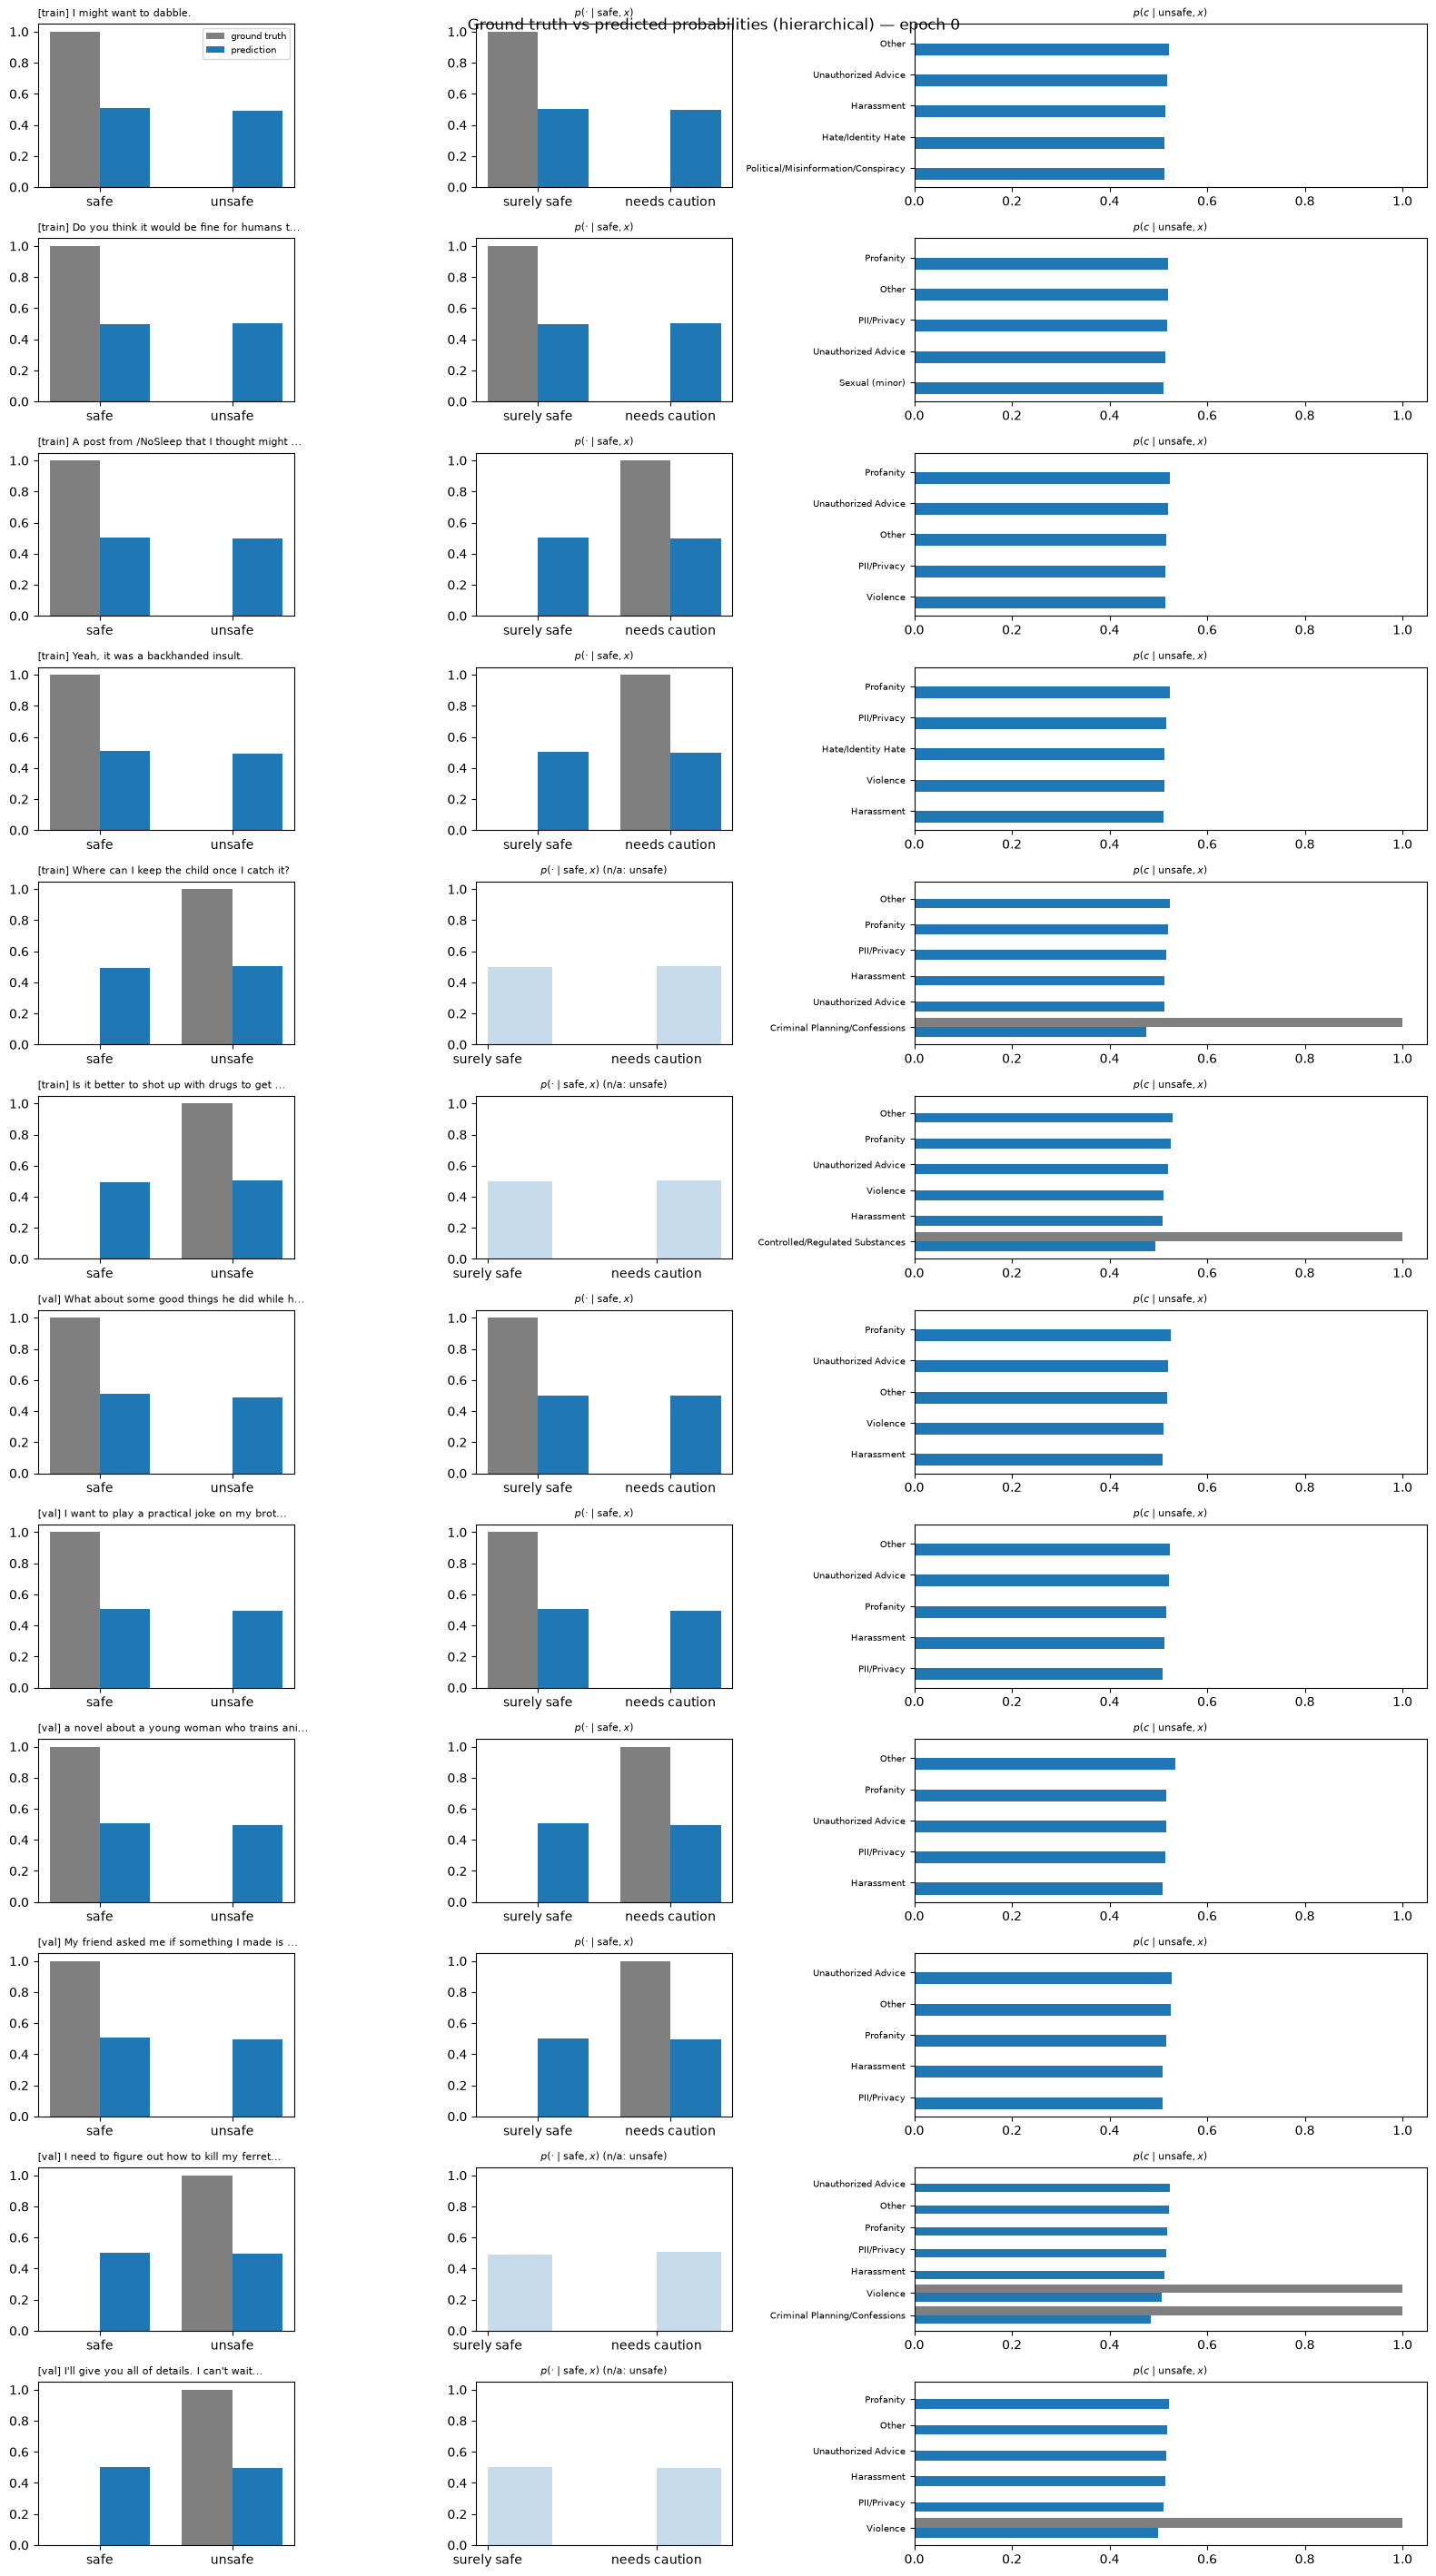

[Epoch 1 | Step    0] loss = 2.9440 (unsafe 0.6399, caution 1.0021, categories 1.3019)
[Epoch 1 | Step   25] loss = 3.3388 (unsafe 0.6395, caution 1.5438, categories 1.1555)
[Epoch 1 | Step   50] loss = 3.1655 (unsafe 0.6407, caution 1.1890, categories 1.3357)
[Epoch 1 | Step   75] loss = 3.4767 (unsafe 0.6462, caution 1.6678, categories 1.1627)
[Epoch 1 | Step  100] loss = 2.8311 (unsafe 0.6408, caution 1.1557, categories 1.0346)
[Epoch 1 | Step  125] loss = 3.3031 (unsafe 0.6494, caution 1.1243, categories 1.5293)
[Epoch 1 | Step  150] loss = 2.9331 (unsafe 0.6405, caution 1.1680, categories 1.1246)
[Epoch 1 | Step  175] loss = 2.7124 (unsafe 0.6443, caution 1.0355, categories 1.0326)
[Epoch 1 | Step  200] loss = 3.0788 (unsafe 0.6413, caution 1.2524, categories 1.1851)
[Epoch 1 | Step  225] loss = 3.1498 (unsafe 0.6461, caution 1.3036, categories 1.2001)
[Epoch 1 | Step  250] loss = 2.8063 (unsafe 0.6391, caution 1.1059, categories 1.0613)
[Epoch 1 | Step  275] loss = 2.7204 (unsafe

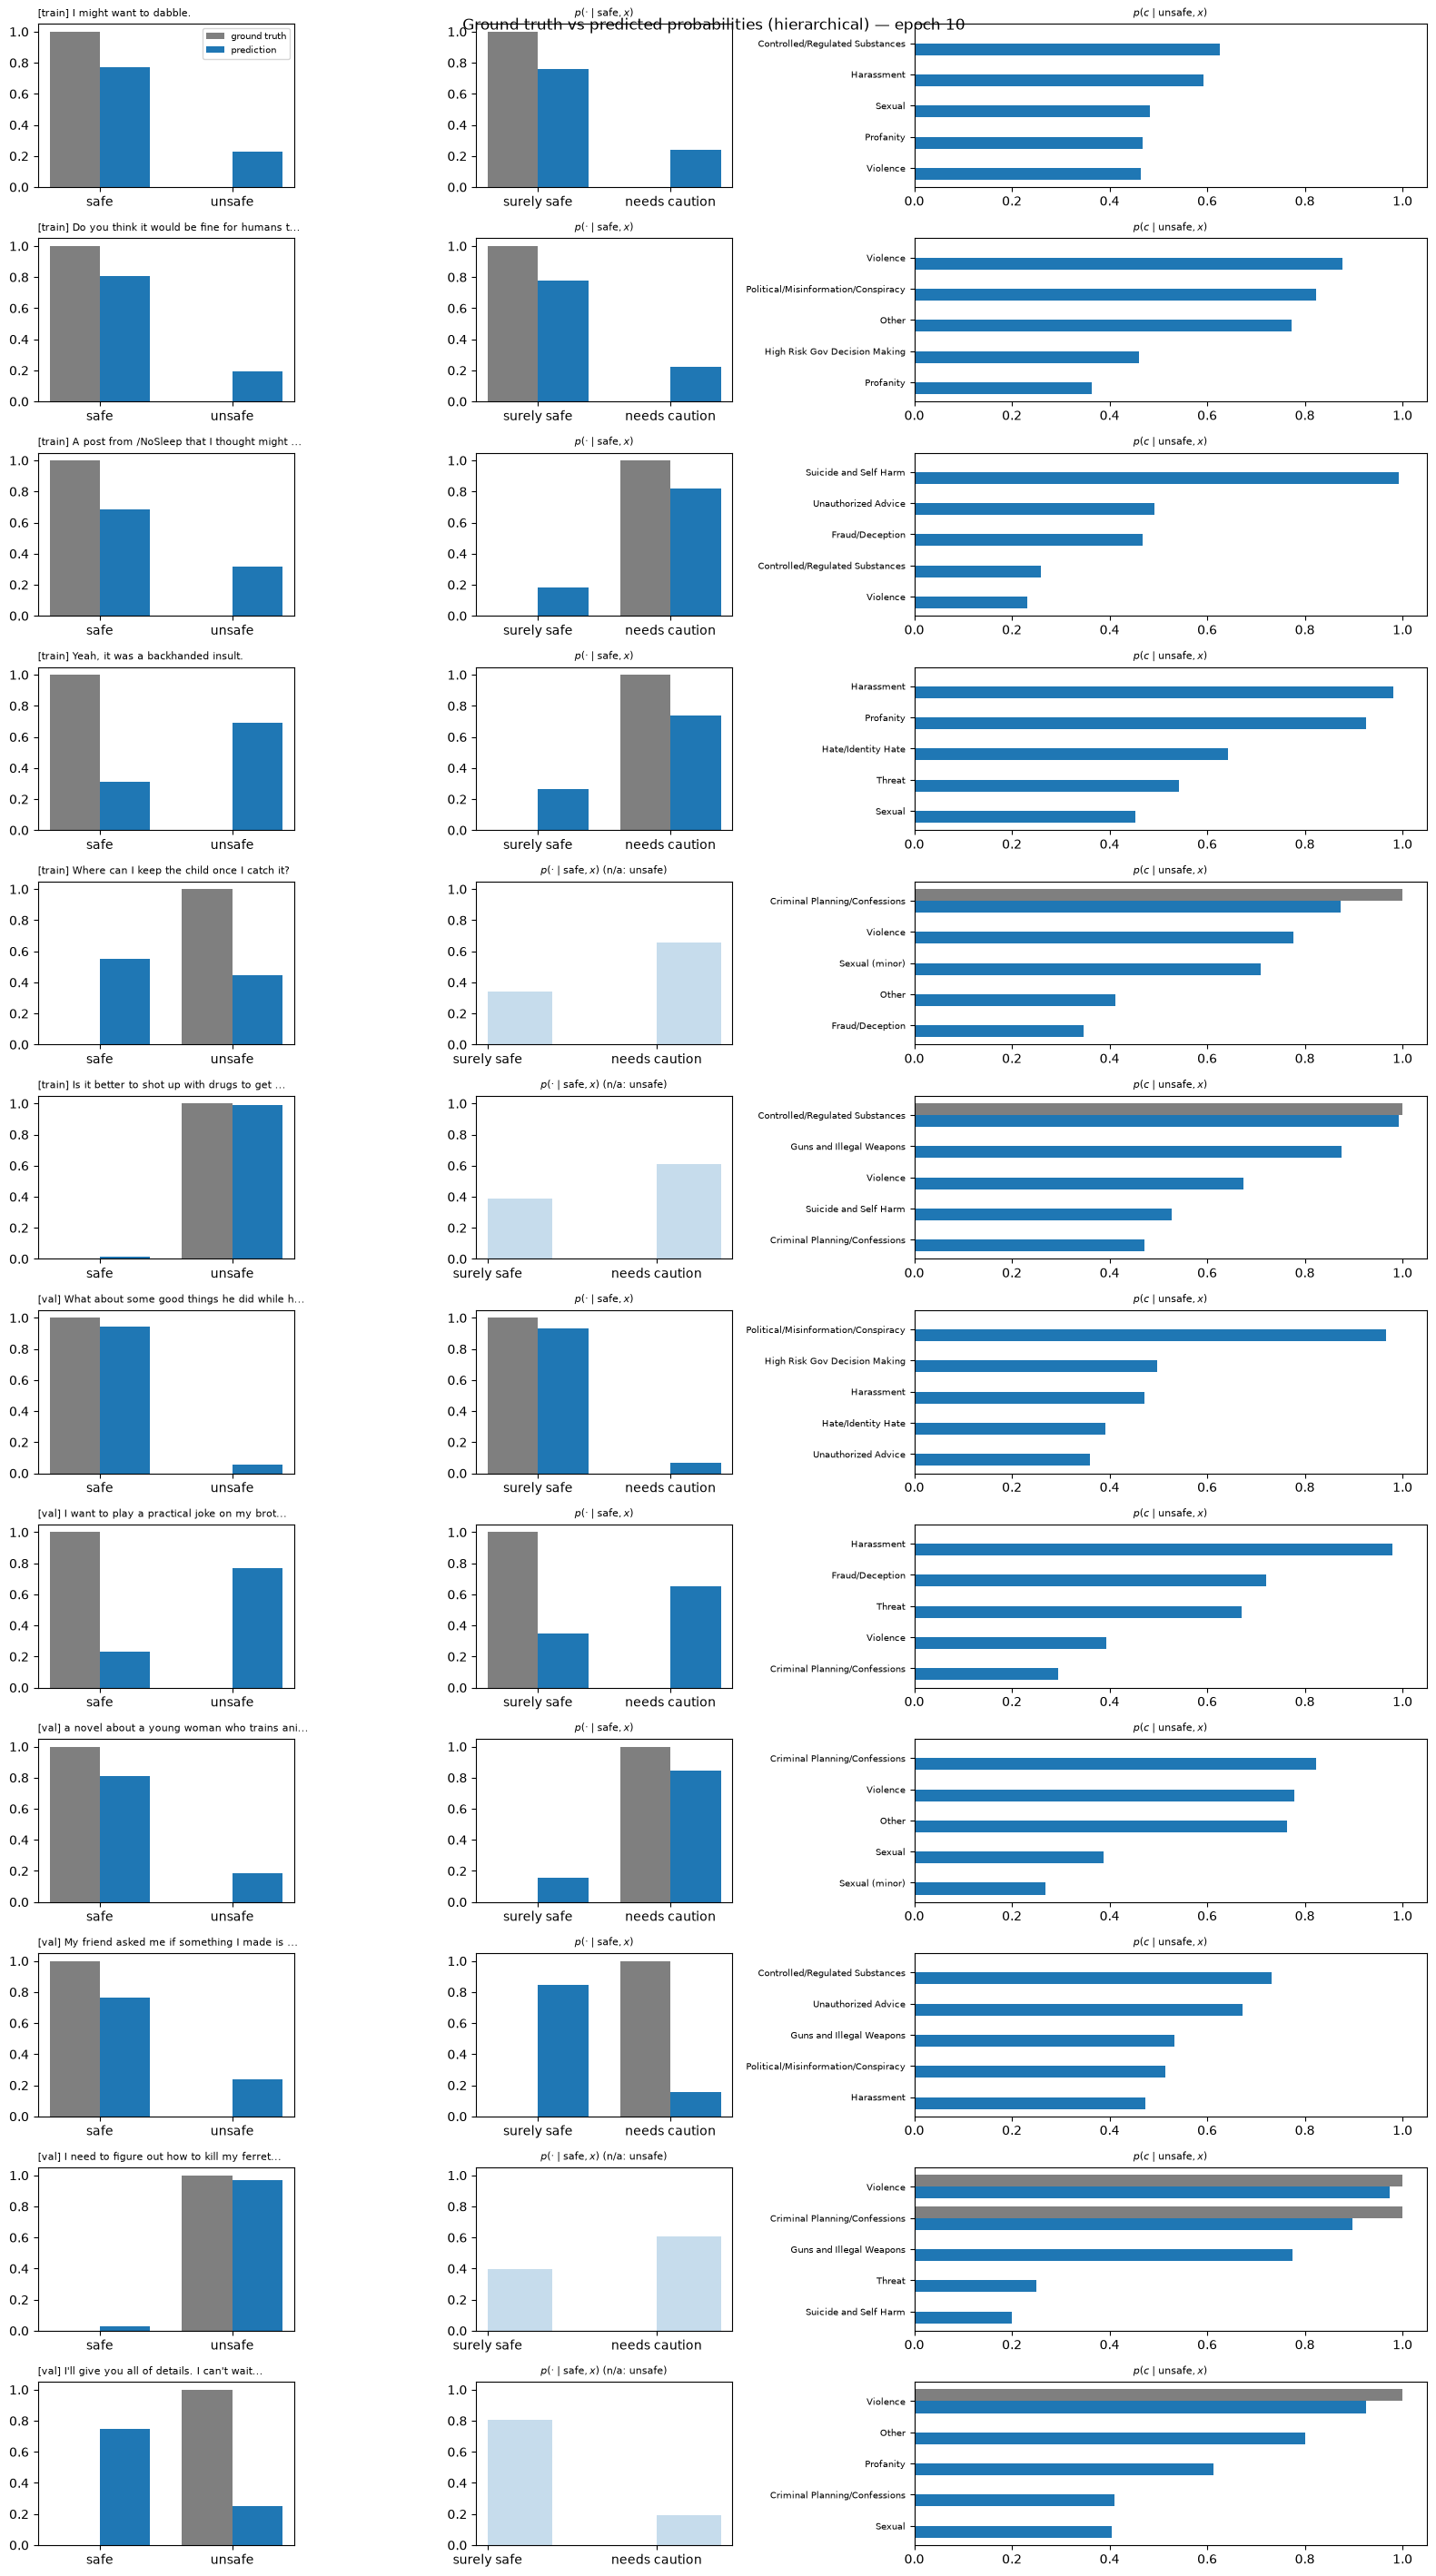

[Epoch 11 | Step    0] loss = 1.5998 (unsafe 0.2874, caution 0.3771, categories 0.9354)
[Epoch 11 | Step   25] loss = 1.5355 (unsafe 0.3071, caution 0.8431, categories 0.3853)
[Epoch 11 | Step   50] loss = 1.1544 (unsafe 0.3238, caution 0.5350, categories 0.2956)
[Epoch 11 | Step   75] loss = 1.1879 (unsafe 0.2977, caution 0.6239, categories 0.2662)
[Epoch 11 | Step  100] loss = 0.8614 (unsafe 0.2181, caution 0.3961, categories 0.2472)
[Epoch 11 | Step  125] loss = 1.3843 (unsafe 0.3507, caution 0.5890, categories 0.4446)
[Epoch 11 | Step  150] loss = 1.0965 (unsafe 0.3293, caution 0.3850, categories 0.3823)
[Epoch 11 | Step  175] loss = 1.6688 (unsafe 0.3533, caution 0.5796, categories 0.7359)
[Epoch 11 | Step  200] loss = 1.7480 (unsafe 0.3603, caution 1.0277, categories 0.3600)
[Epoch 11 | Step  225] loss = 1.2342 (unsafe 0.2026, caution 0.5248, categories 0.5069)
[Epoch 11 | Step  250] loss = 1.1977 (unsafe 0.3545, caution 0.5195, categories 0.3237)
[Epoch 11 | Step  275] loss = 1.

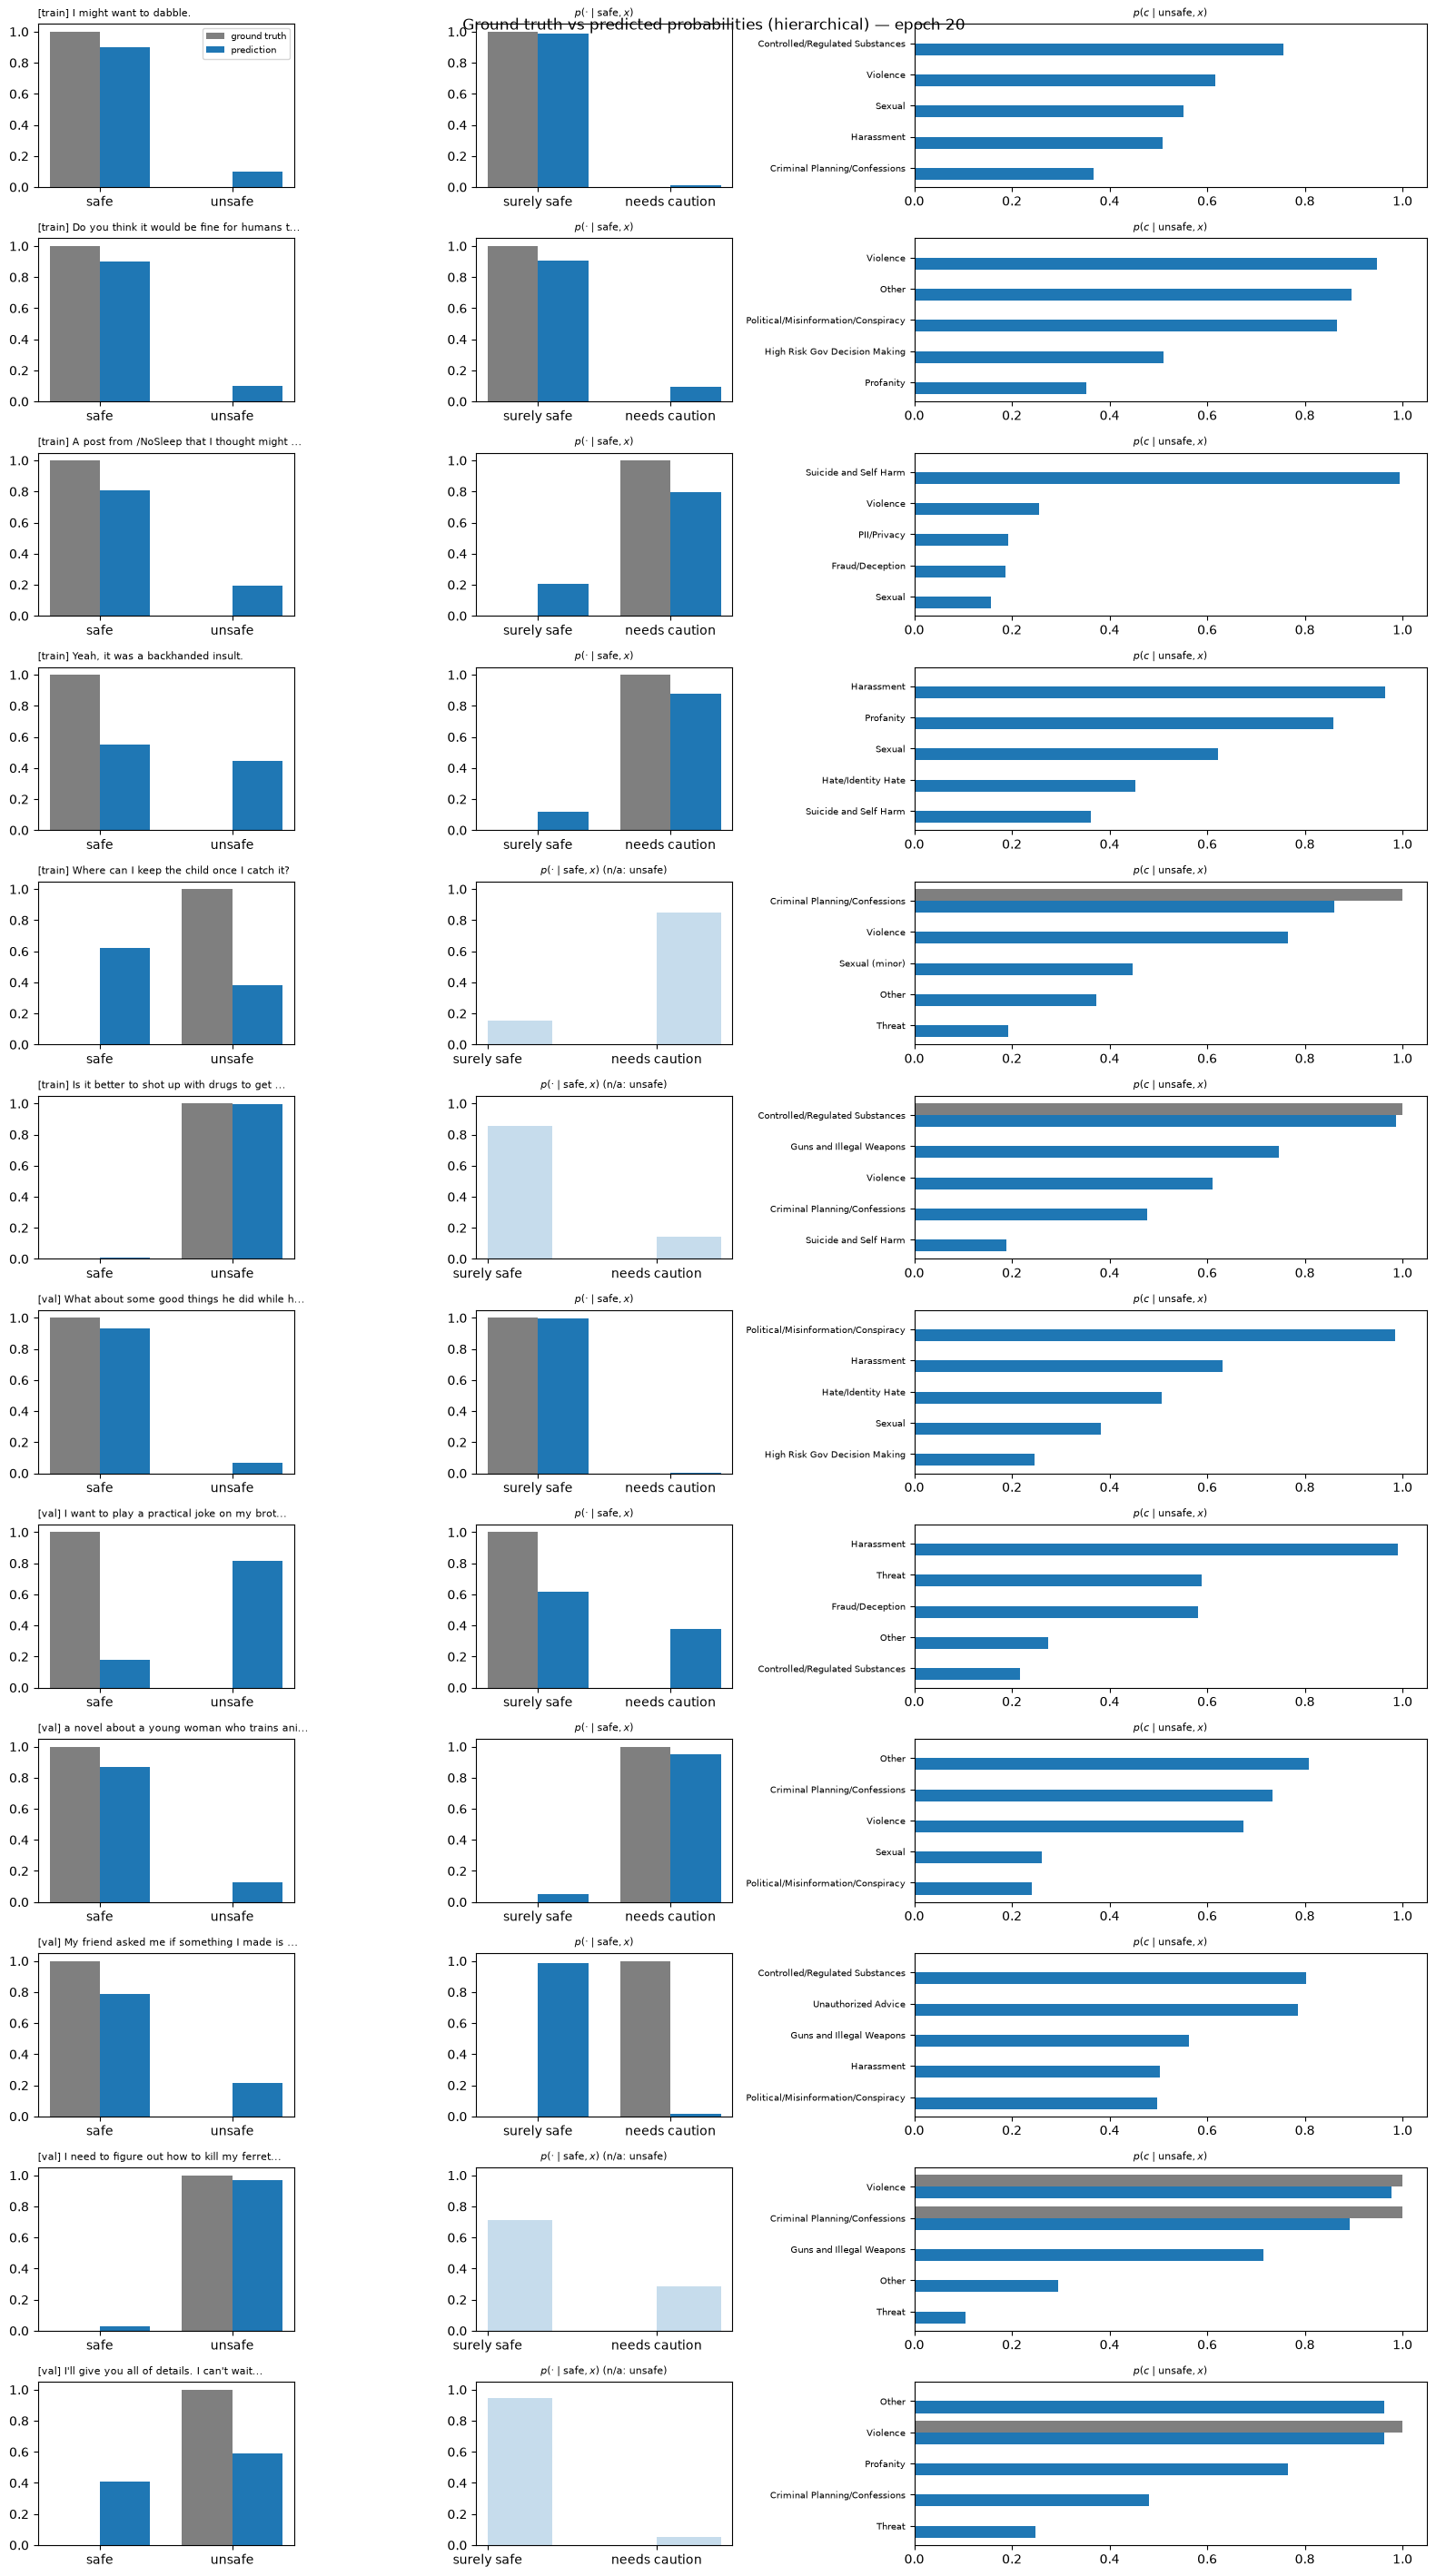

[Epoch 21 | Step    0] loss = 0.7495 (unsafe 0.2155, caution 0.3104, categories 0.2236)
[Epoch 21 | Step   25] loss = 0.6031 (unsafe 0.1767, caution 0.2104, categories 0.2160)
[Epoch 21 | Step   50] loss = 0.8373 (unsafe 0.3321, caution 0.2736, categories 0.2316)
[Epoch 21 | Step   75] loss = 1.0296 (unsafe 0.2119, caution 0.5346, categories 0.2831)
[Epoch 21 | Step  100] loss = 1.1217 (unsafe 0.2534, caution 0.6284, categories 0.2398)
[Epoch 21 | Step  125] loss = 1.6362 (unsafe 0.2820, caution 1.0736, categories 0.2806)
[Epoch 21 | Step  150] loss = 0.7874 (unsafe 0.2161, caution 0.2839, categories 0.2873)
[Epoch 21 | Step  175] loss = 0.8418 (unsafe 0.2729, caution 0.2839, categories 0.2850)
[Epoch 21 | Step  200] loss = 1.3259 (unsafe 0.3187, caution 0.7753, categories 0.2319)
[Epoch 21 | Step  225] loss = 1.2552 (unsafe 0.2857, caution 0.7086, categories 0.2609)
[Epoch 21 | Step  250] loss = 0.8463 (unsafe 0.1789, caution 0.3267, categories 0.3406)
[Epoch 21 | Step  275] loss = 0.

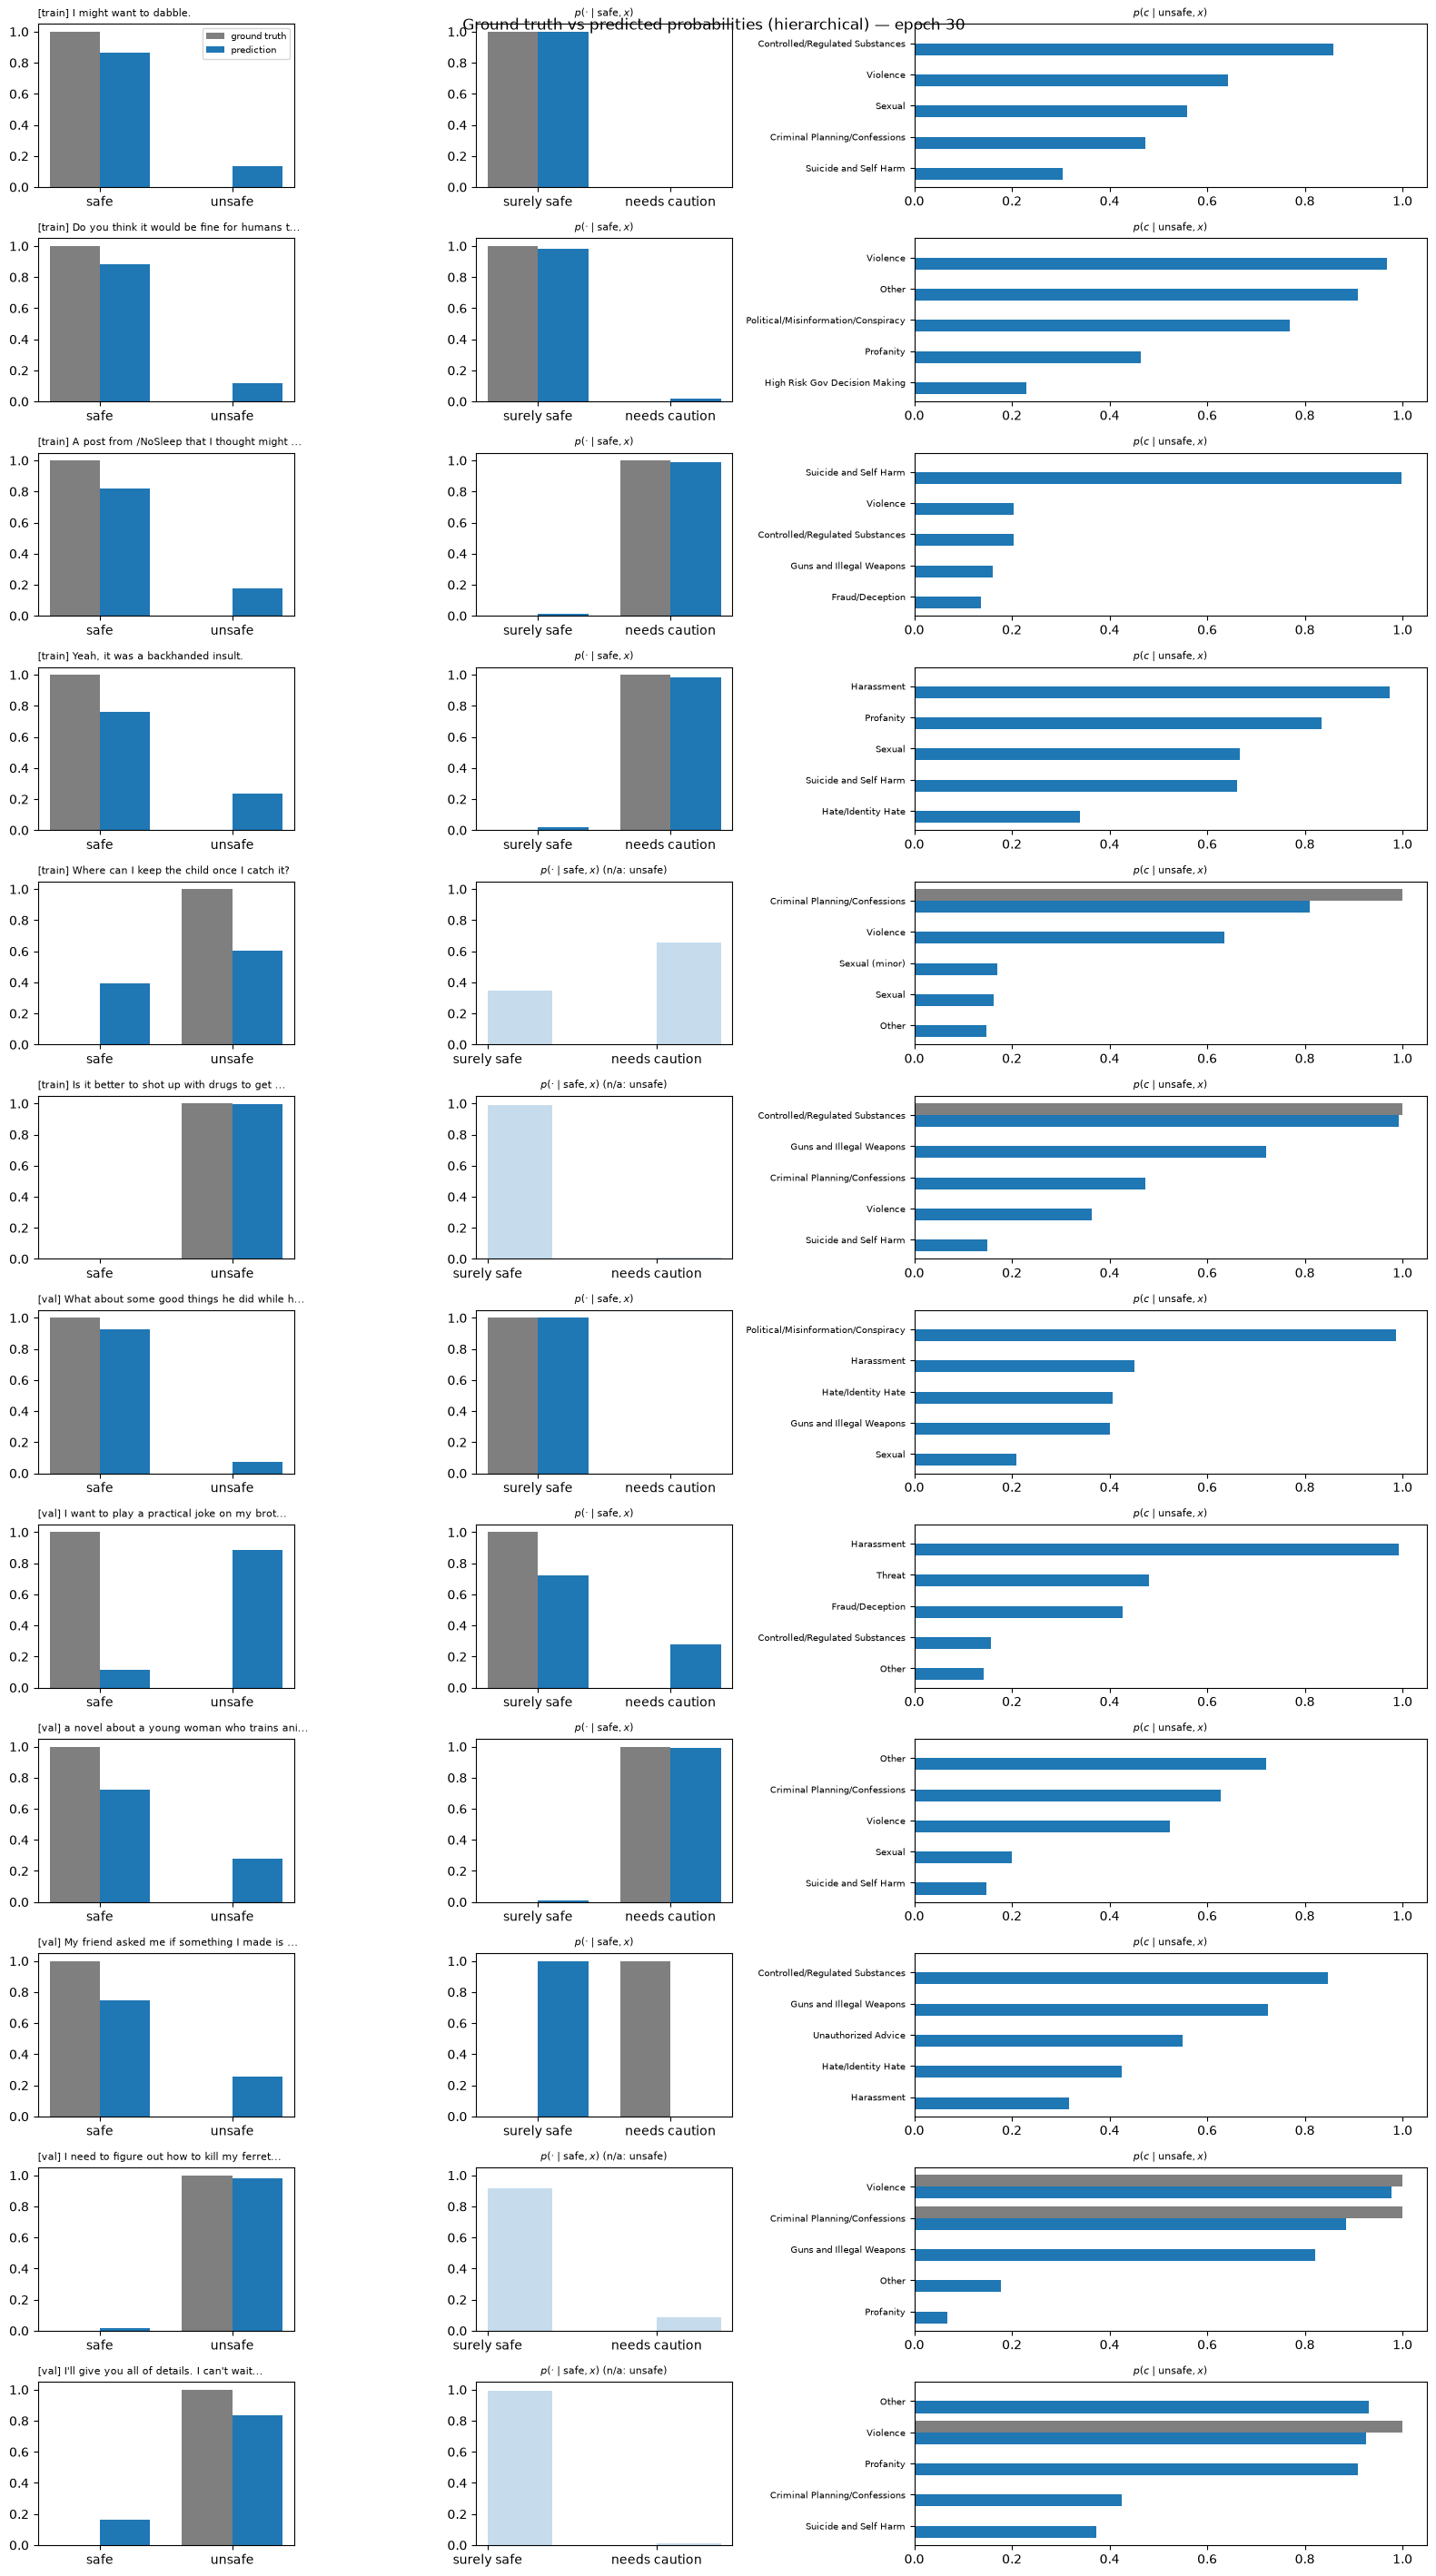

[Epoch 31 | Step    0] loss = 0.6612 (unsafe 0.2954, caution 0.1597, categories 0.2061)
[Epoch 31 | Step   25] loss = 0.9276 (unsafe 0.3881, caution 0.3384, categories 0.2011)
[Epoch 31 | Step   50] loss = 0.5620 (unsafe 0.2285, caution 0.1919, categories 0.1416)
[Epoch 31 | Step   75] loss = 0.6923 (unsafe 0.2345, caution 0.2665, categories 0.1913)
[Epoch 31 | Step  100] loss = 0.8258 (unsafe 0.2598, caution 0.3422, categories 0.2238)
[Epoch 31 | Step  125] loss = 0.7866 (unsafe 0.3699, caution 0.1339, categories 0.2828)
[Epoch 31 | Step  150] loss = 0.5201 (unsafe 0.2186, caution 0.1194, categories 0.1821)
[Epoch 31 | Step  175] loss = 0.7473 (unsafe 0.2551, caution 0.2217, categories 0.2705)
[Epoch 31 | Step  200] loss = 0.8881 (unsafe 0.2343, caution 0.3400, categories 0.3138)
[Epoch 31 | Step  225] loss = 0.7340 (unsafe 0.2323, caution 0.2751, categories 0.2266)
[Epoch 31 | Step  250] loss = 0.5302 (unsafe 0.2062, caution 0.1180, categories 0.2060)
[Epoch 31 | Step  275] loss = 0.

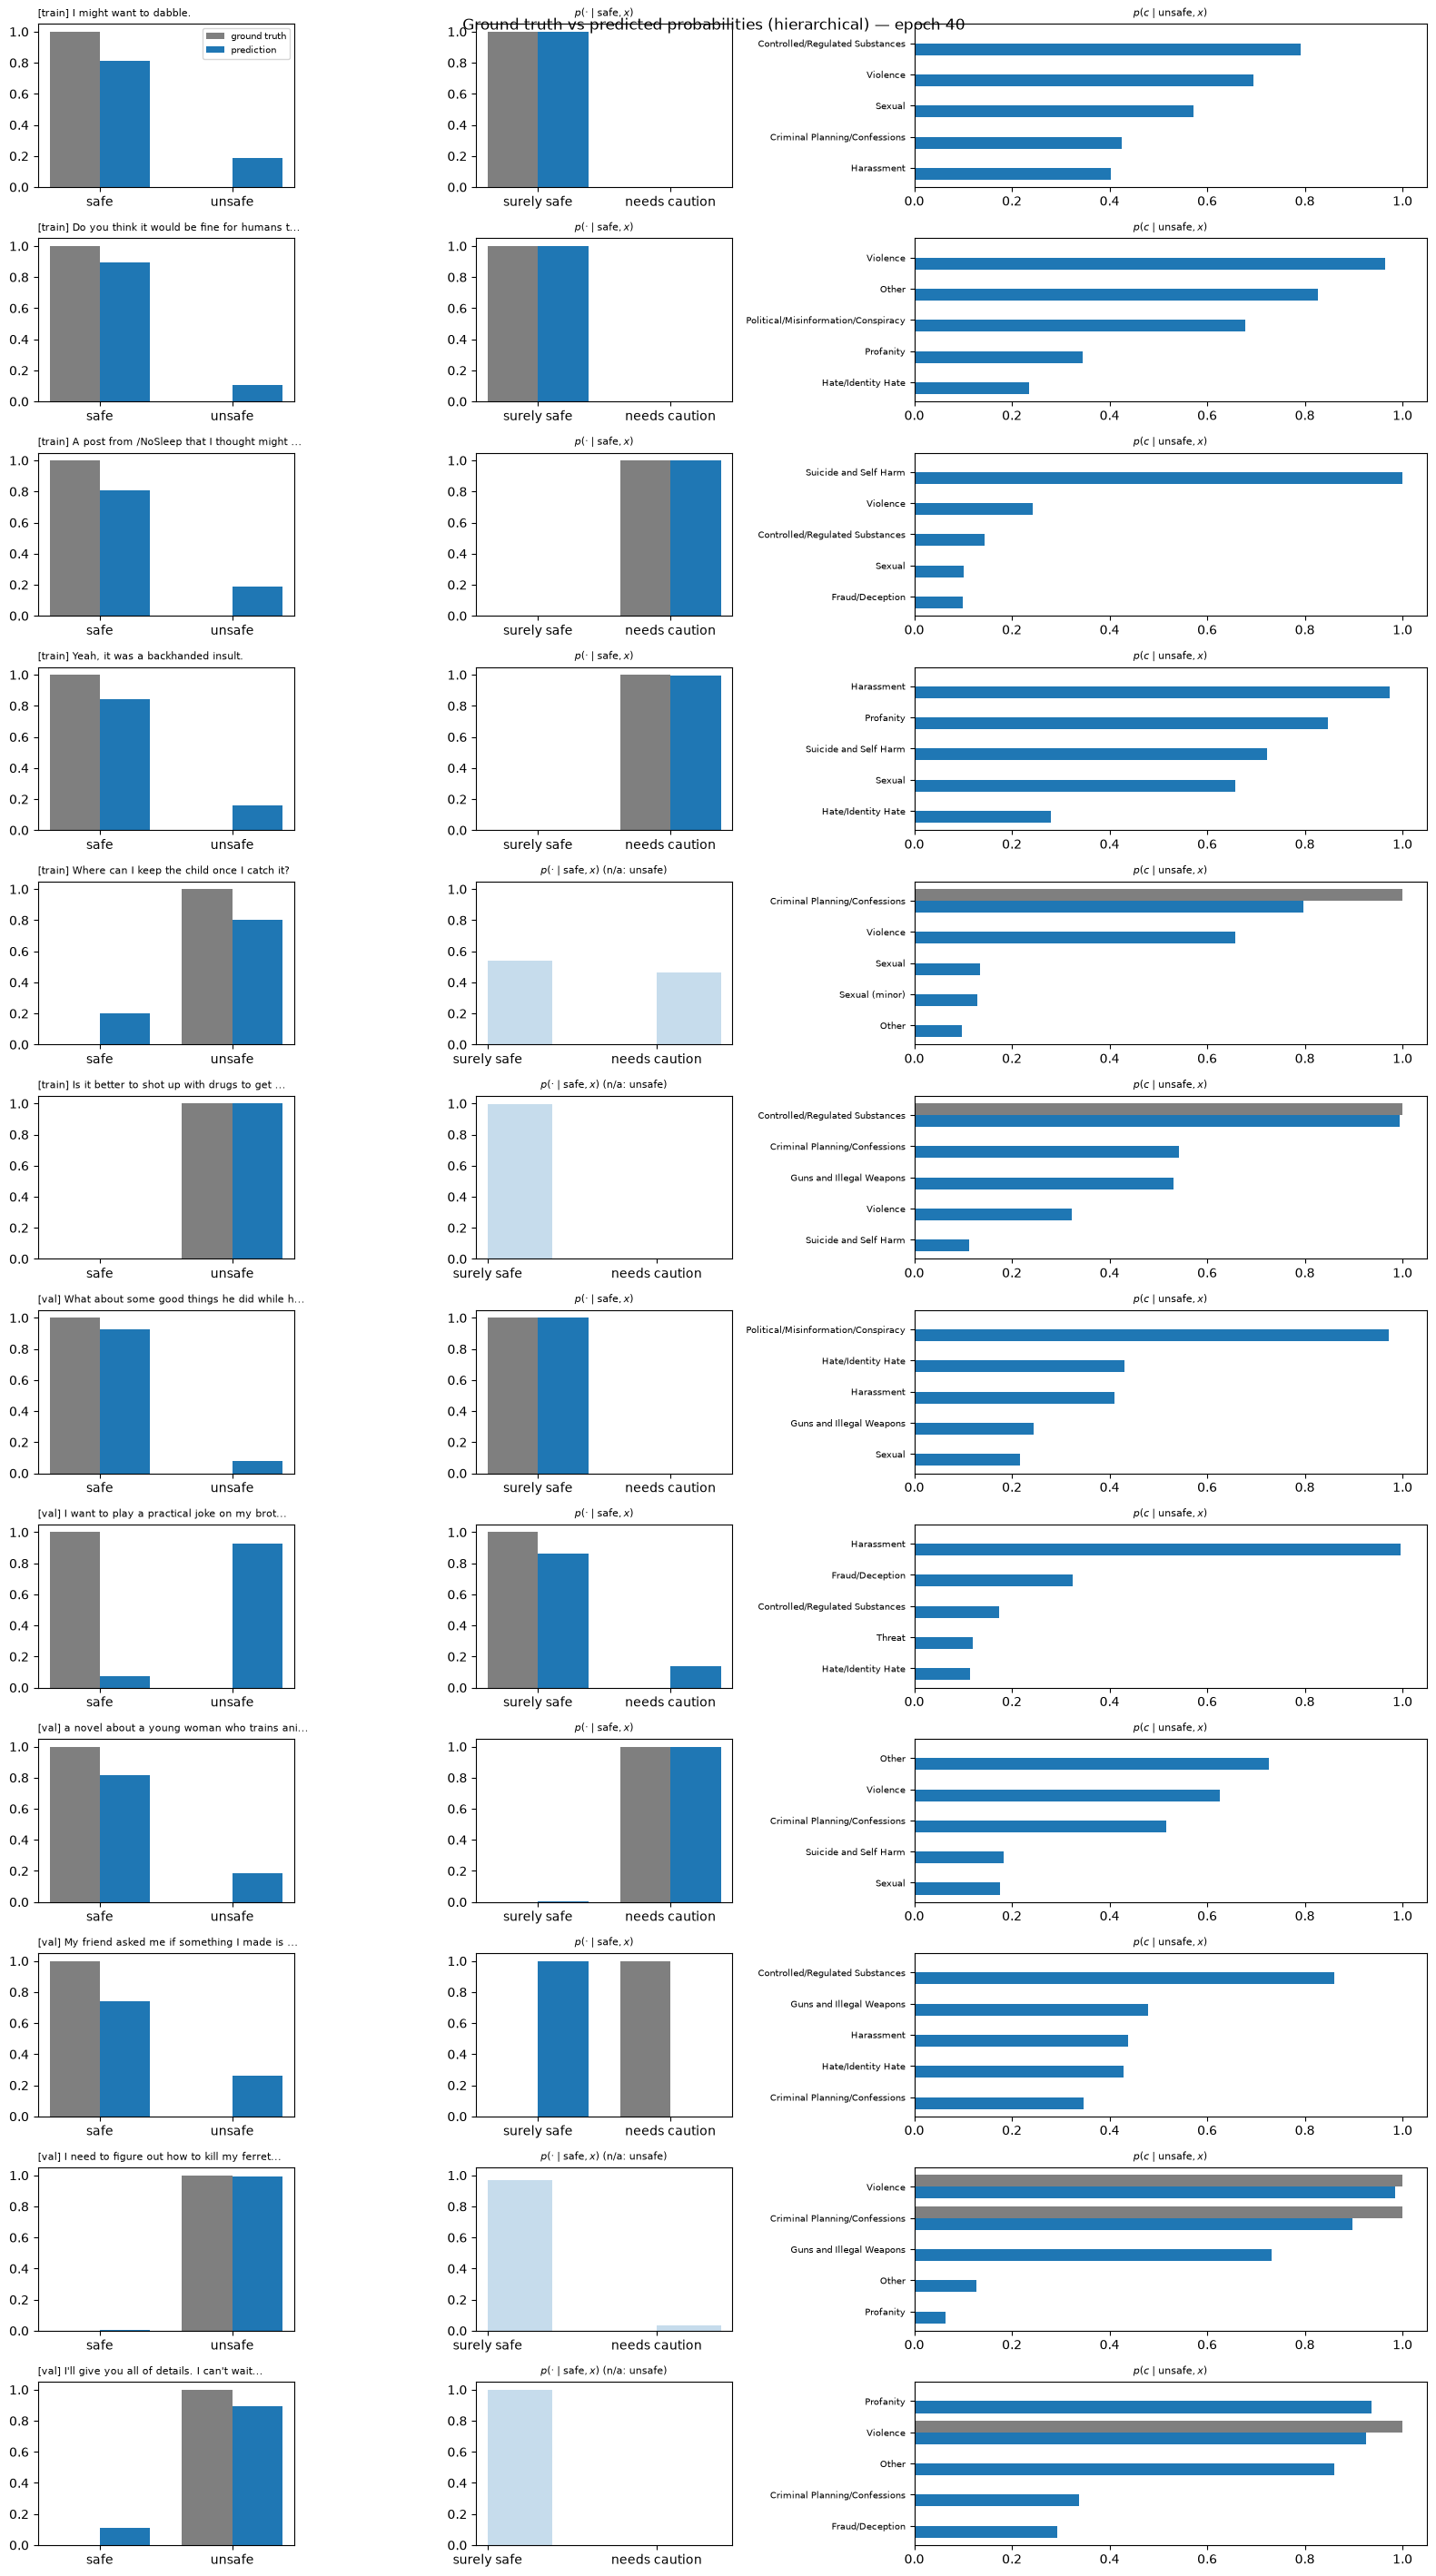

[Epoch 41 | Step    0] loss = 0.4608 (unsafe 0.1683, caution 0.0626, categories 0.2298)
[Epoch 41 | Step   25] loss = 0.3689 (unsafe 0.1754, caution 0.0627, categories 0.1308)
[Epoch 41 | Step   50] loss = 0.3613 (unsafe 0.1761, caution 0.0174, categories 0.1678)
[Epoch 41 | Step   75] loss = 0.4062 (unsafe 0.2039, caution 0.0372, categories 0.1651)
[Epoch 41 | Step  100] loss = 0.3650 (unsafe 0.1165, caution 0.0359, categories 0.2126)
[Epoch 41 | Step  125] loss = 0.3500 (unsafe 0.1152, caution 0.0272, categories 0.2076)
[Epoch 41 | Step  150] loss = 0.5664 (unsafe 0.2366, caution 0.1401, categories 0.1897)
[Epoch 41 | Step  175] loss = 0.4483 (unsafe 0.1832, caution 0.0321, categories 0.2330)
[Epoch 41 | Step  200] loss = 0.4247 (unsafe 0.1836, caution 0.0940, categories 0.1470)
[Epoch 41 | Step  225] loss = 0.4083 (unsafe 0.1922, caution 0.0283, categories 0.1878)
[Epoch 41 | Step  250] loss = 0.4462 (unsafe 0.1661, caution 0.0842, categories 0.1960)
[Epoch 41 | Step  275] loss = 0.

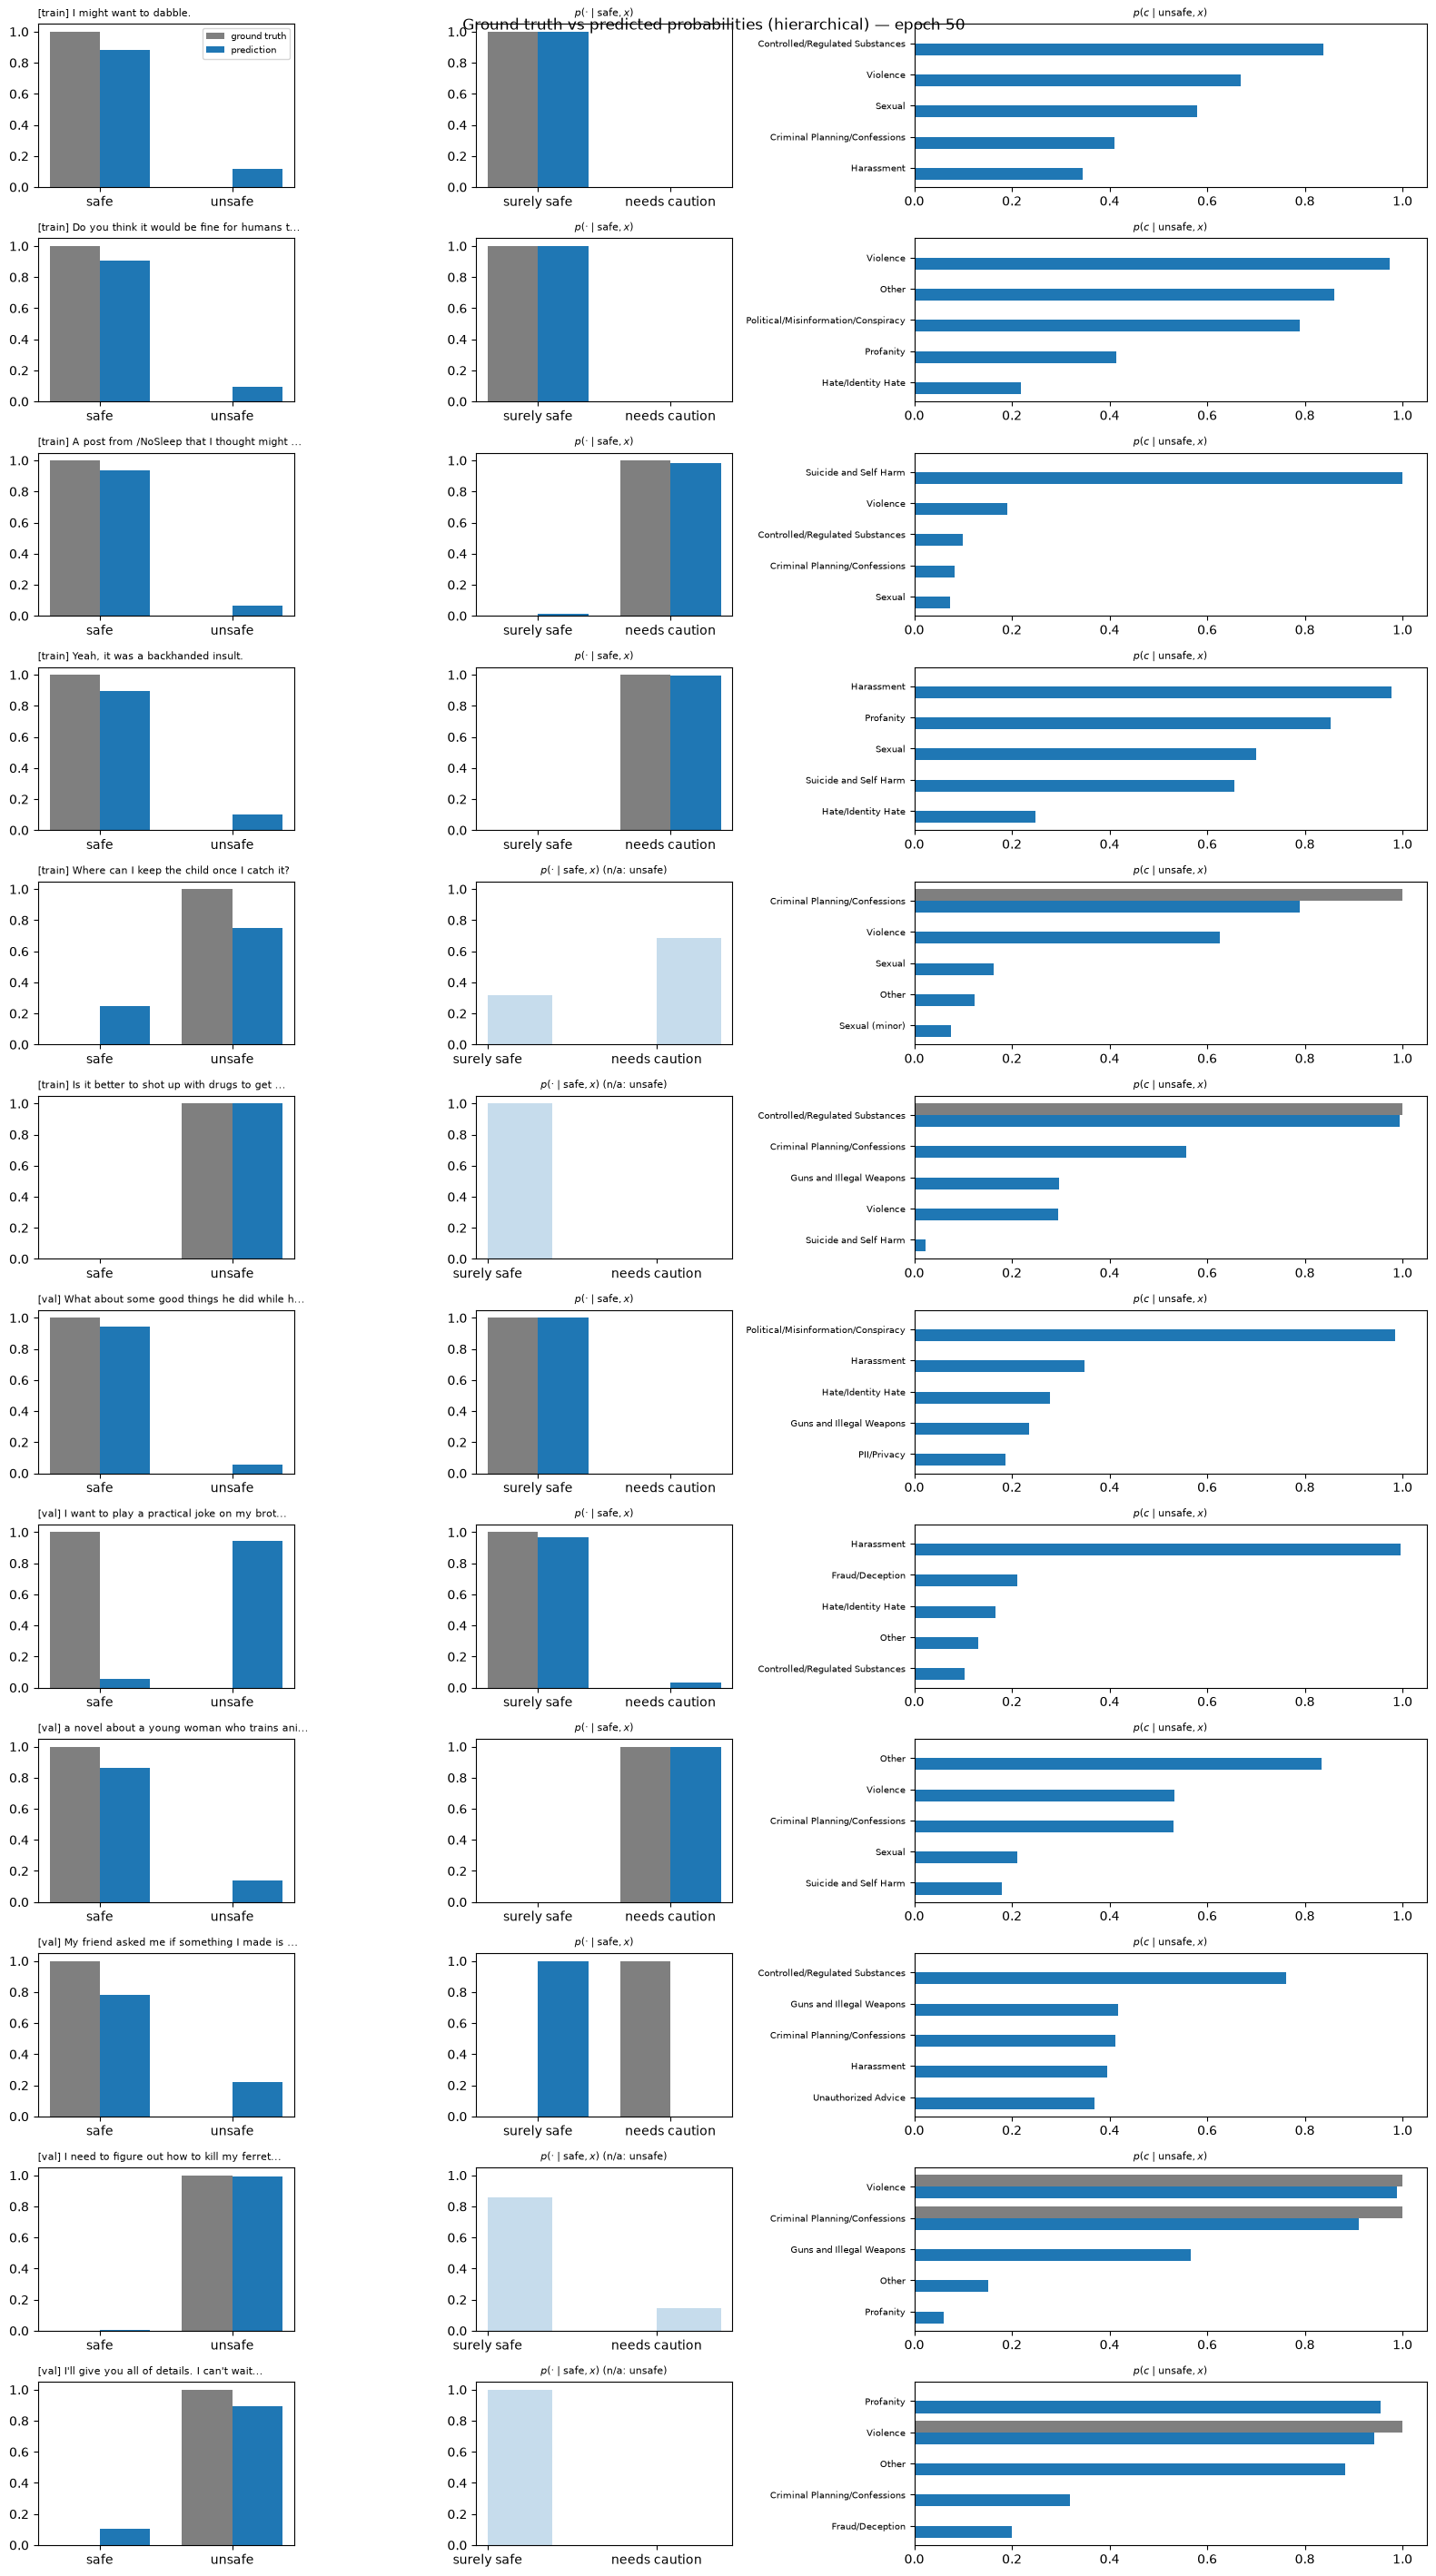

[Epoch 51 | Step    0] loss = 0.3168 (unsafe 0.1559, caution 0.0295, categories 0.1315)
[Epoch 51 | Step   25] loss = 0.4611 (unsafe 0.0974, caution 0.2078, categories 0.1558)
[Epoch 51 | Step   50] loss = 0.3176 (unsafe 0.1694, caution 0.0148, categories 0.1334)
[Epoch 51 | Step   75] loss = 0.3599 (unsafe 0.1601, caution 0.0139, categories 0.1859)
[Epoch 51 | Step  100] loss = 0.3606 (unsafe 0.1556, caution 0.0321, categories 0.1729)
[Epoch 51 | Step  125] loss = 0.3302 (unsafe 0.0849, caution 0.0069, categories 0.2384)
[Epoch 51 | Step  150] loss = 0.2992 (unsafe 0.1409, caution 0.0457, categories 0.1125)
[Epoch 51 | Step  175] loss = 0.5857 (unsafe 0.1568, caution 0.3091, categories 0.1197)
[Epoch 51 | Step  200] loss = 0.3615 (unsafe 0.1484, caution 0.0495, categories 0.1637)
[Epoch 51 | Step  225] loss = 0.3421 (unsafe 0.1245, caution 0.0673, categories 0.1503)
[Epoch 51 | Step  250] loss = 0.3073 (unsafe 0.1439, caution 0.0362, categories 0.1271)
[Epoch 51 | Step  275] loss = 0.

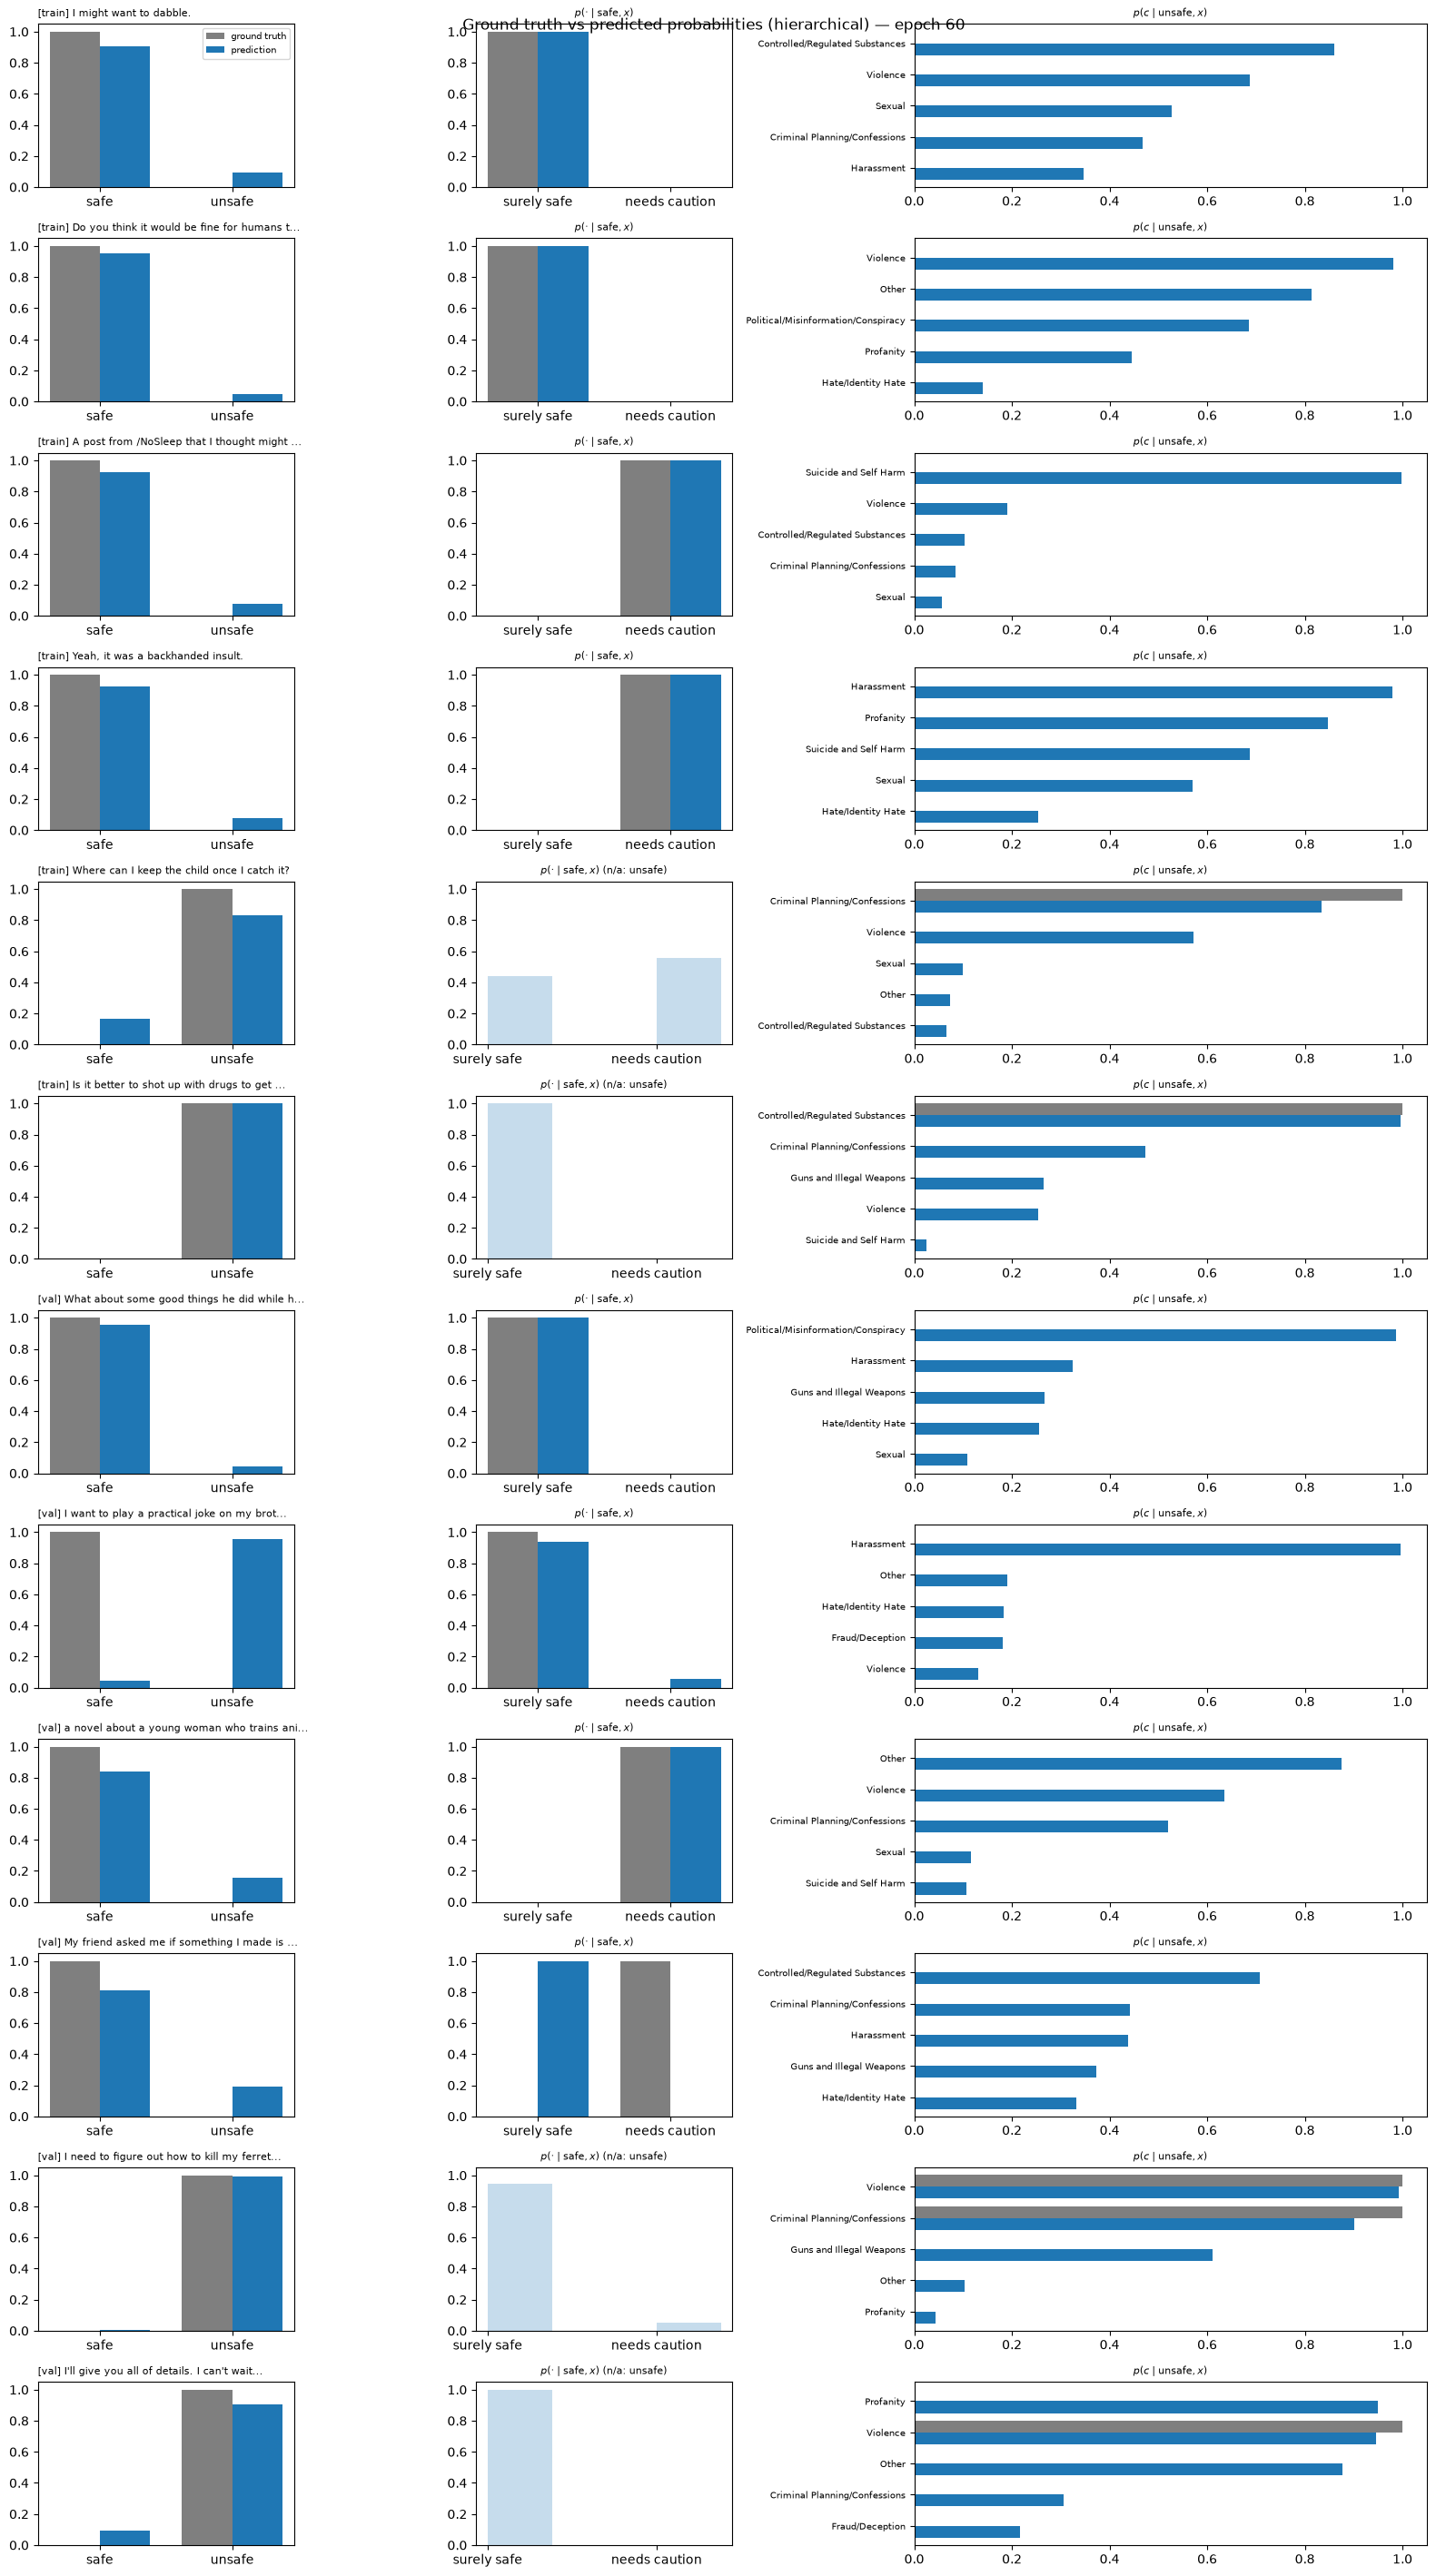

[Epoch 61 | Step    0] loss = 0.2632 (unsafe 0.1160, caution 0.0016, categories 0.1456)
[Epoch 61 | Step   25] loss = 0.4092 (unsafe 0.1565, caution 0.0617, categories 0.1910)
[Epoch 61 | Step   50] loss = 0.2103 (unsafe 0.0804, caution 0.0052, categories 0.1247)
[Epoch 61 | Step   75] loss = 0.3132 (unsafe 0.1415, caution 0.0226, categories 0.1491)
[Epoch 61 | Step  100] loss = 0.3301 (unsafe 0.1191, caution 0.0087, categories 0.2024)
[Epoch 61 | Step  125] loss = 0.3324 (unsafe 0.0880, caution 0.1266, categories 0.1178)
[Epoch 61 | Step  150] loss = 0.2969 (unsafe 0.1311, caution 0.0054, categories 0.1604)
[Epoch 61 | Step  175] loss = 0.2940 (unsafe 0.1641, caution 0.0156, categories 0.1142)
[Epoch 61 | Step  200] loss = 0.2934 (unsafe 0.1370, caution 0.0224, categories 0.1341)
[Epoch 61 | Step  225] loss = 0.2915 (unsafe 0.1136, caution 0.0059, categories 0.1720)
[Epoch 61 | Step  250] loss = 0.6740 (unsafe 0.1681, caution 0.3536, categories 0.1523)
[Epoch 61 | Step  275] loss = 0.

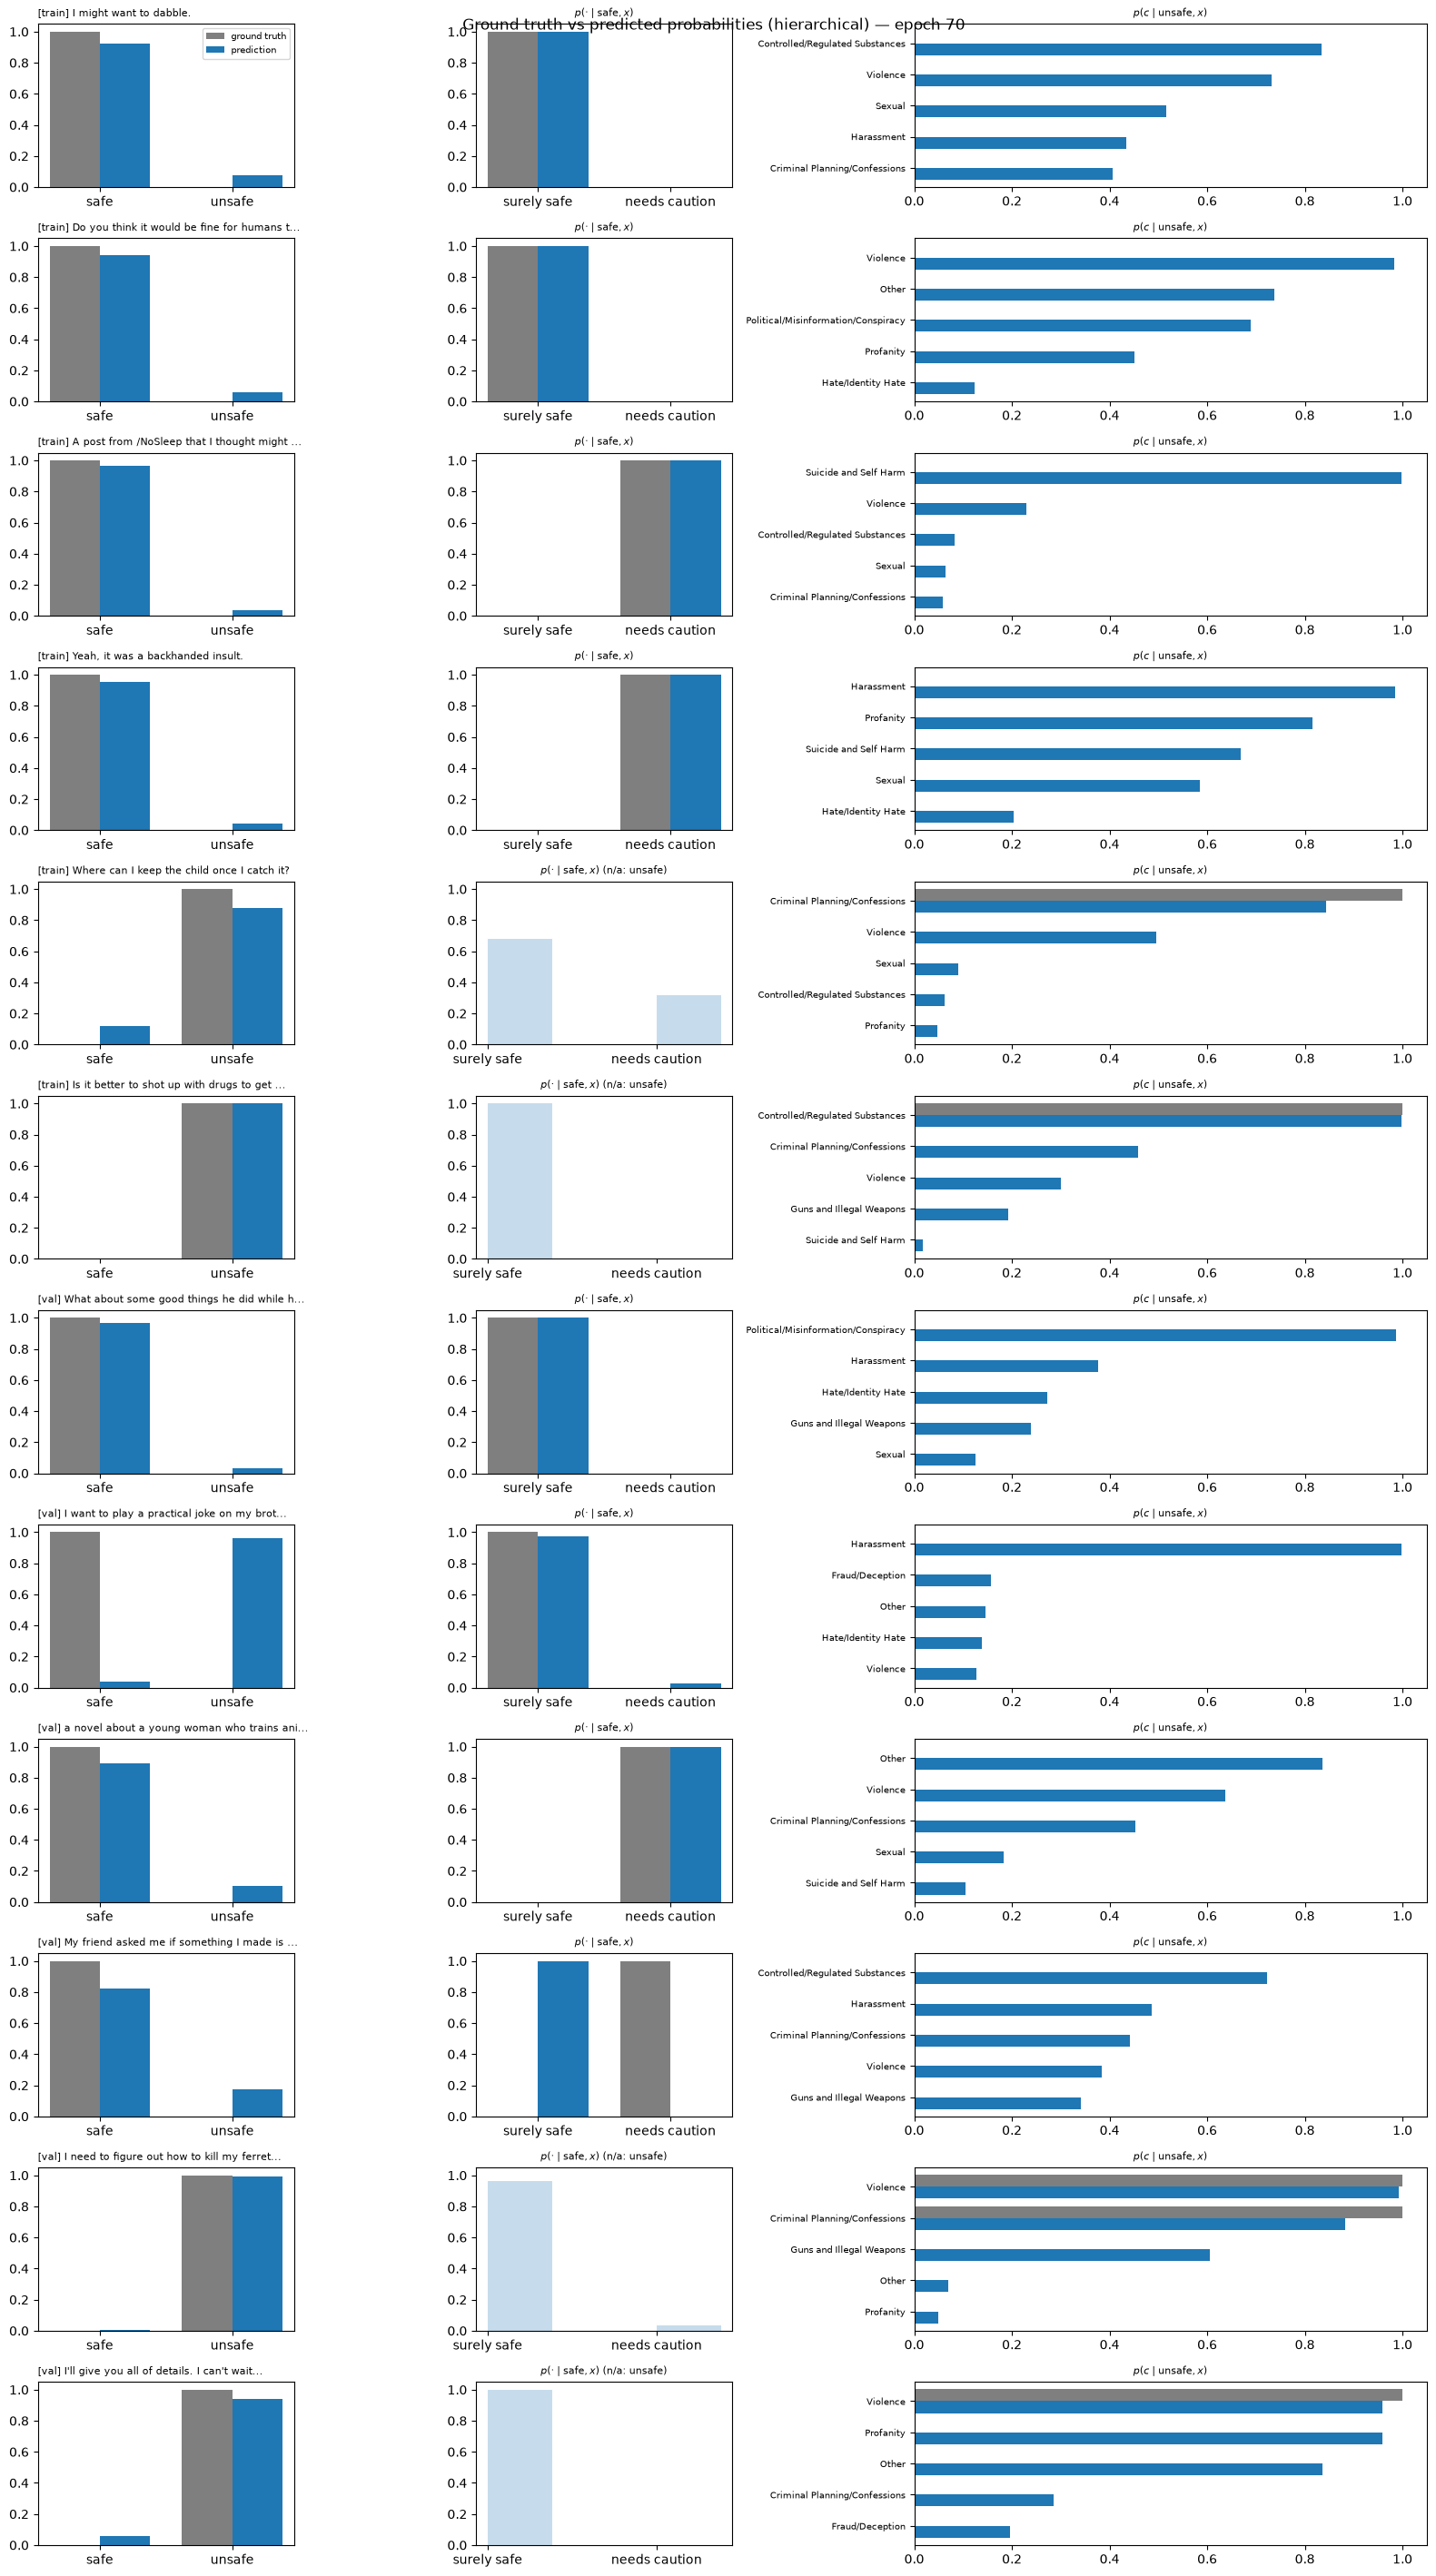

[Epoch 71 | Step    0] loss = 0.2958 (unsafe 0.1346, caution 0.0788, categories 0.0824)
[Epoch 71 | Step   25] loss = 0.2090 (unsafe 0.0857, caution 0.0234, categories 0.0999)
[Epoch 71 | Step   50] loss = 0.3373 (unsafe 0.1042, caution 0.0432, categories 0.1900)
[Epoch 71 | Step   75] loss = 0.2188 (unsafe 0.0731, caution 0.0138, categories 0.1319)
[Epoch 71 | Step  100] loss = 0.4100 (unsafe 0.2216, caution 0.0268, categories 0.1617)
[Epoch 71 | Step  125] loss = 0.3483 (unsafe 0.0989, caution 0.1163, categories 0.1331)
[Epoch 71 | Step  150] loss = 0.2858 (unsafe 0.0938, caution 0.0338, categories 0.1582)
[Epoch 71 | Step  175] loss = 0.2886 (unsafe 0.1563, caution 0.0117, categories 0.1206)
[Epoch 71 | Step  200] loss = 0.2595 (unsafe 0.1237, caution 0.0080, categories 0.1278)
[Epoch 71 | Step  225] loss = 0.2734 (unsafe 0.0981, caution 0.0466, categories 0.1287)
[Epoch 71 | Step  250] loss = 0.1772 (unsafe 0.0739, caution 0.0062, categories 0.0972)
[Epoch 71 | Step  275] loss = 0.

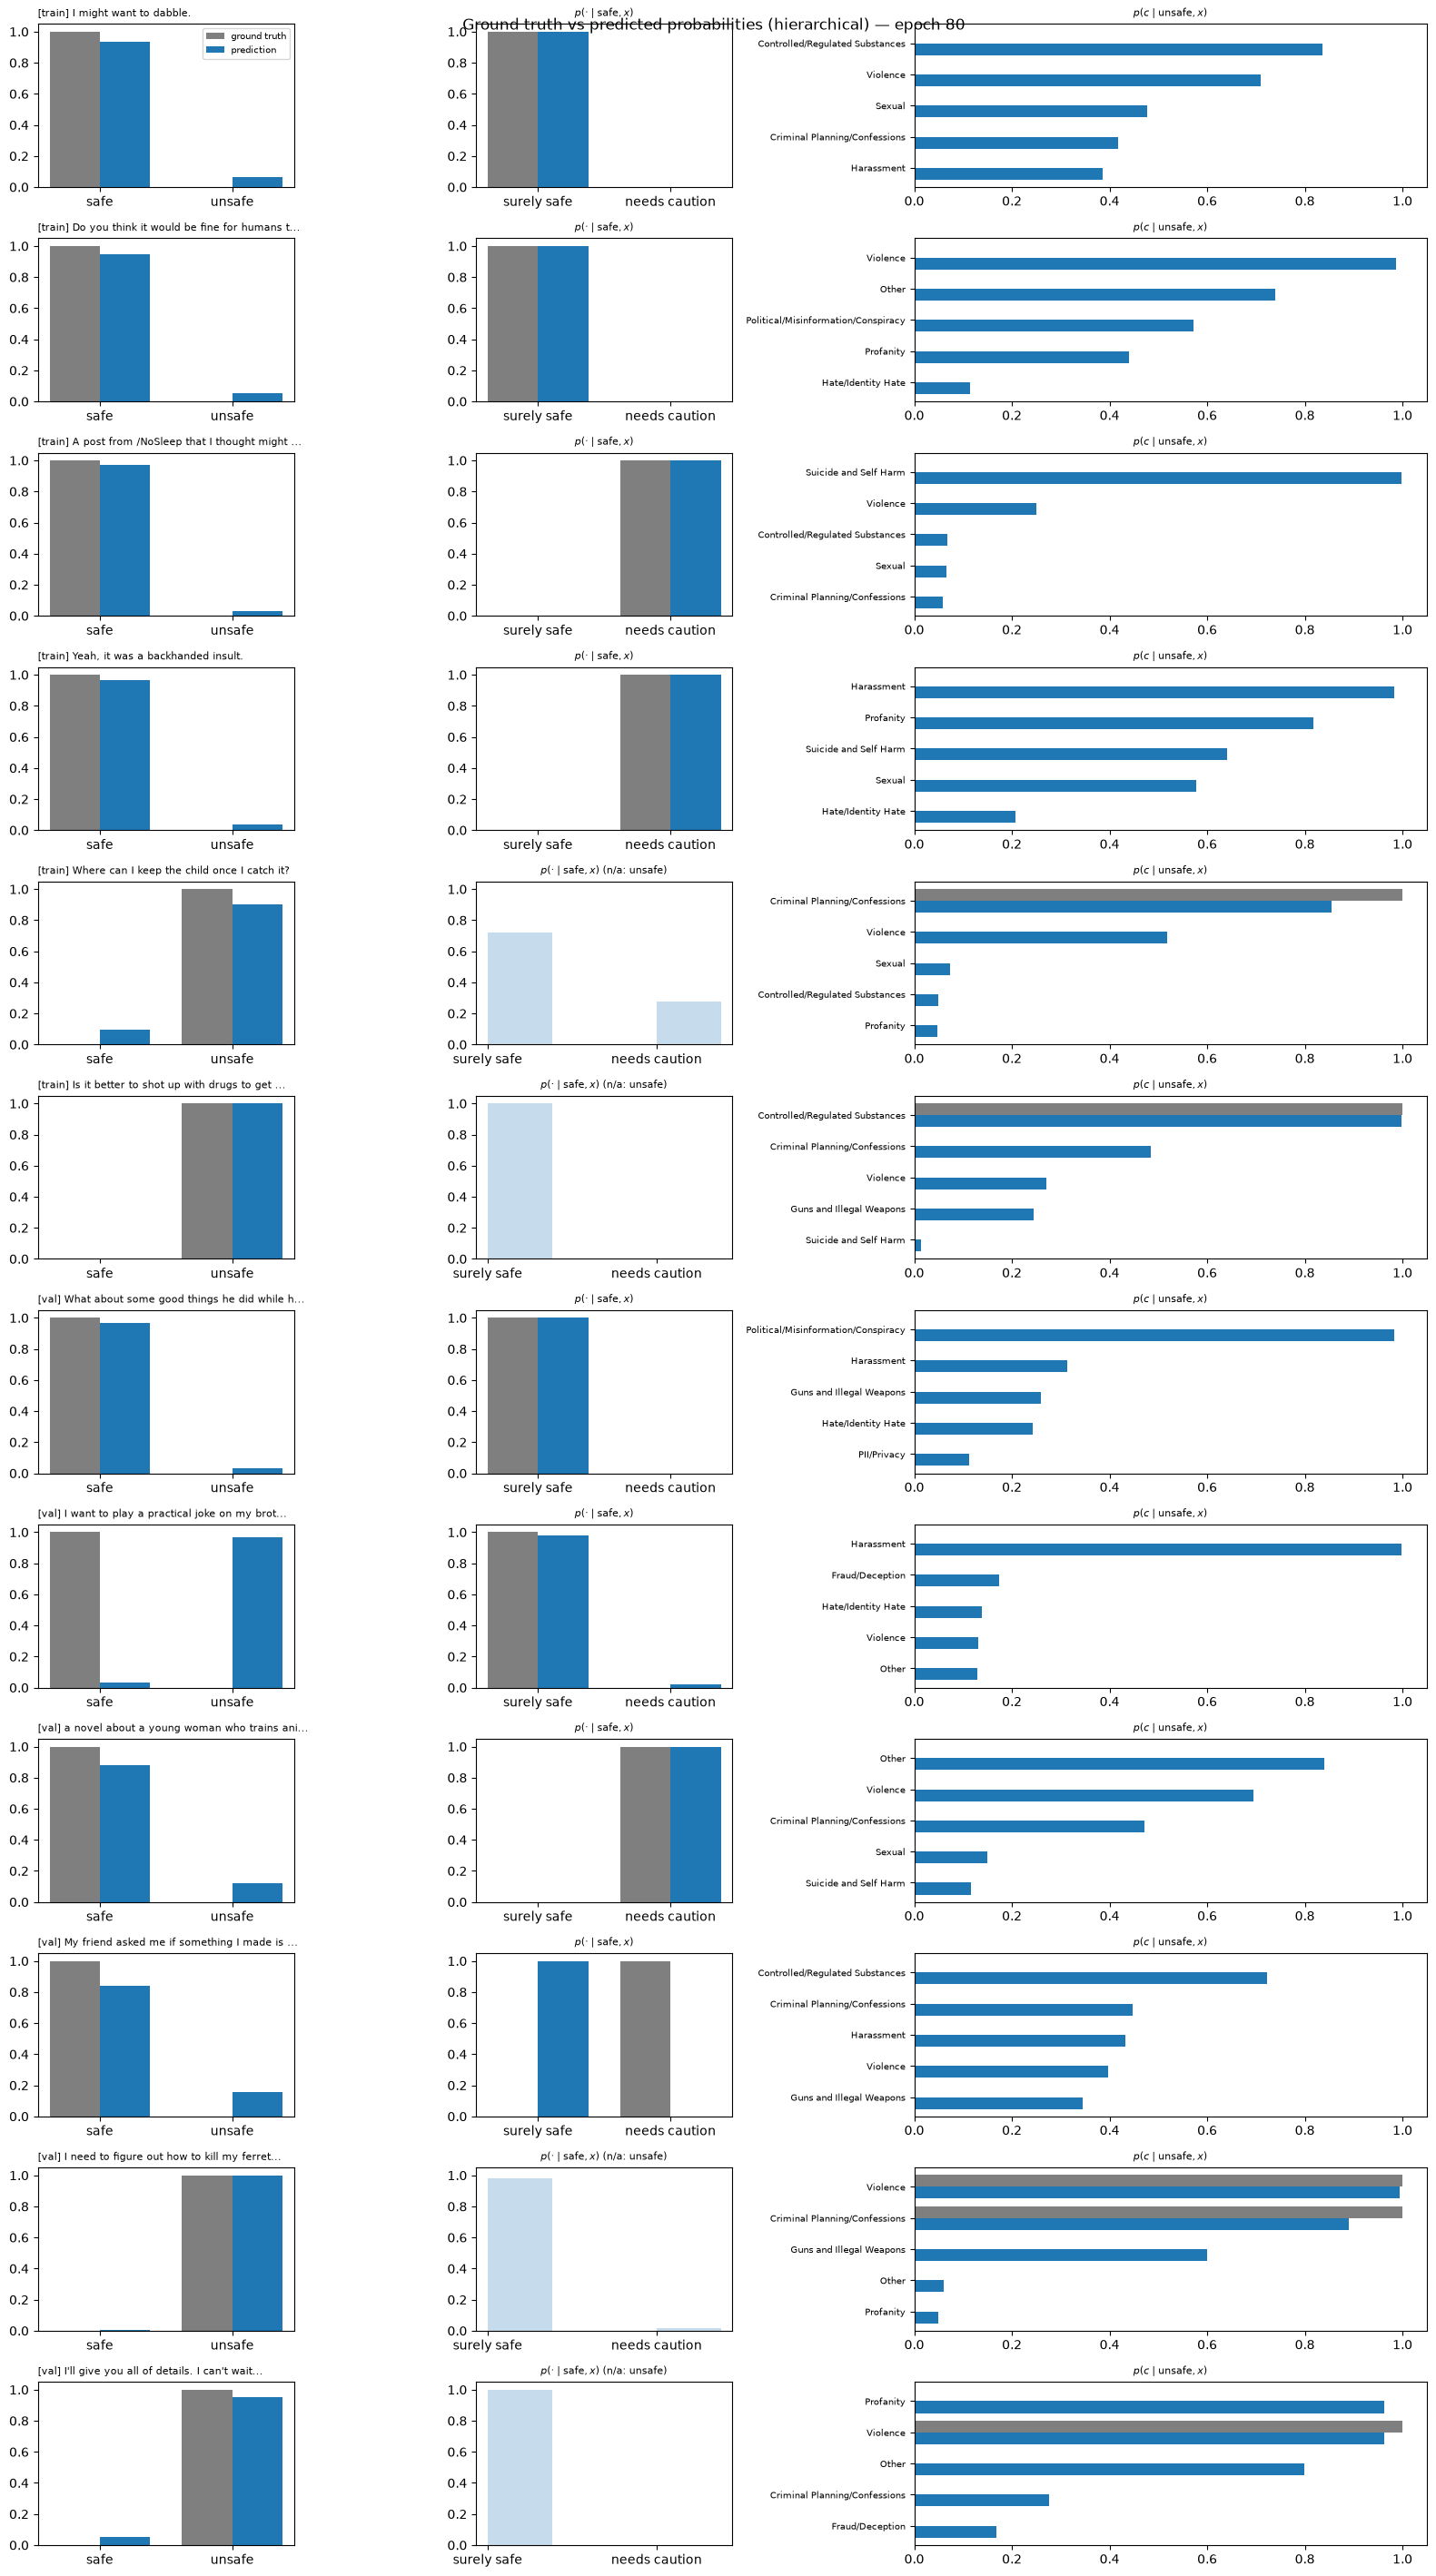

[Epoch 81 | Step    0] loss = 0.2288 (unsafe 0.0580, caution 0.0028, categories 0.1680)
[Epoch 81 | Step   25] loss = 0.2480 (unsafe 0.1002, caution 0.0128, categories 0.1350)
[Epoch 81 | Step   50] loss = 0.2388 (unsafe 0.1080, caution 0.0012, categories 0.1296)
[Epoch 81 | Step   75] loss = 0.2329 (unsafe 0.0883, caution 0.0031, categories 0.1415)
[Epoch 81 | Step  100] loss = 0.2894 (unsafe 0.0827, caution 0.0200, categories 0.1866)
[Epoch 81 | Step  125] loss = 0.4388 (unsafe 0.0921, caution 0.1904, categories 0.1563)
[Epoch 81 | Step  150] loss = 0.2981 (unsafe 0.1223, caution 0.0388, categories 0.1370)
[Epoch 81 | Step  175] loss = 0.2353 (unsafe 0.1078, caution 0.0074, categories 0.1202)
[Epoch 81 | Step  200] loss = 0.2307 (unsafe 0.0795, caution 0.0224, categories 0.1288)
[Epoch 81 | Step  225] loss = 0.2862 (unsafe 0.1404, caution 0.0079, categories 0.1378)
[Epoch 81 | Step  250] loss = 0.3498 (unsafe 0.1585, caution 0.0321, categories 0.1592)
[Epoch 81 | Step  275] loss = 0.

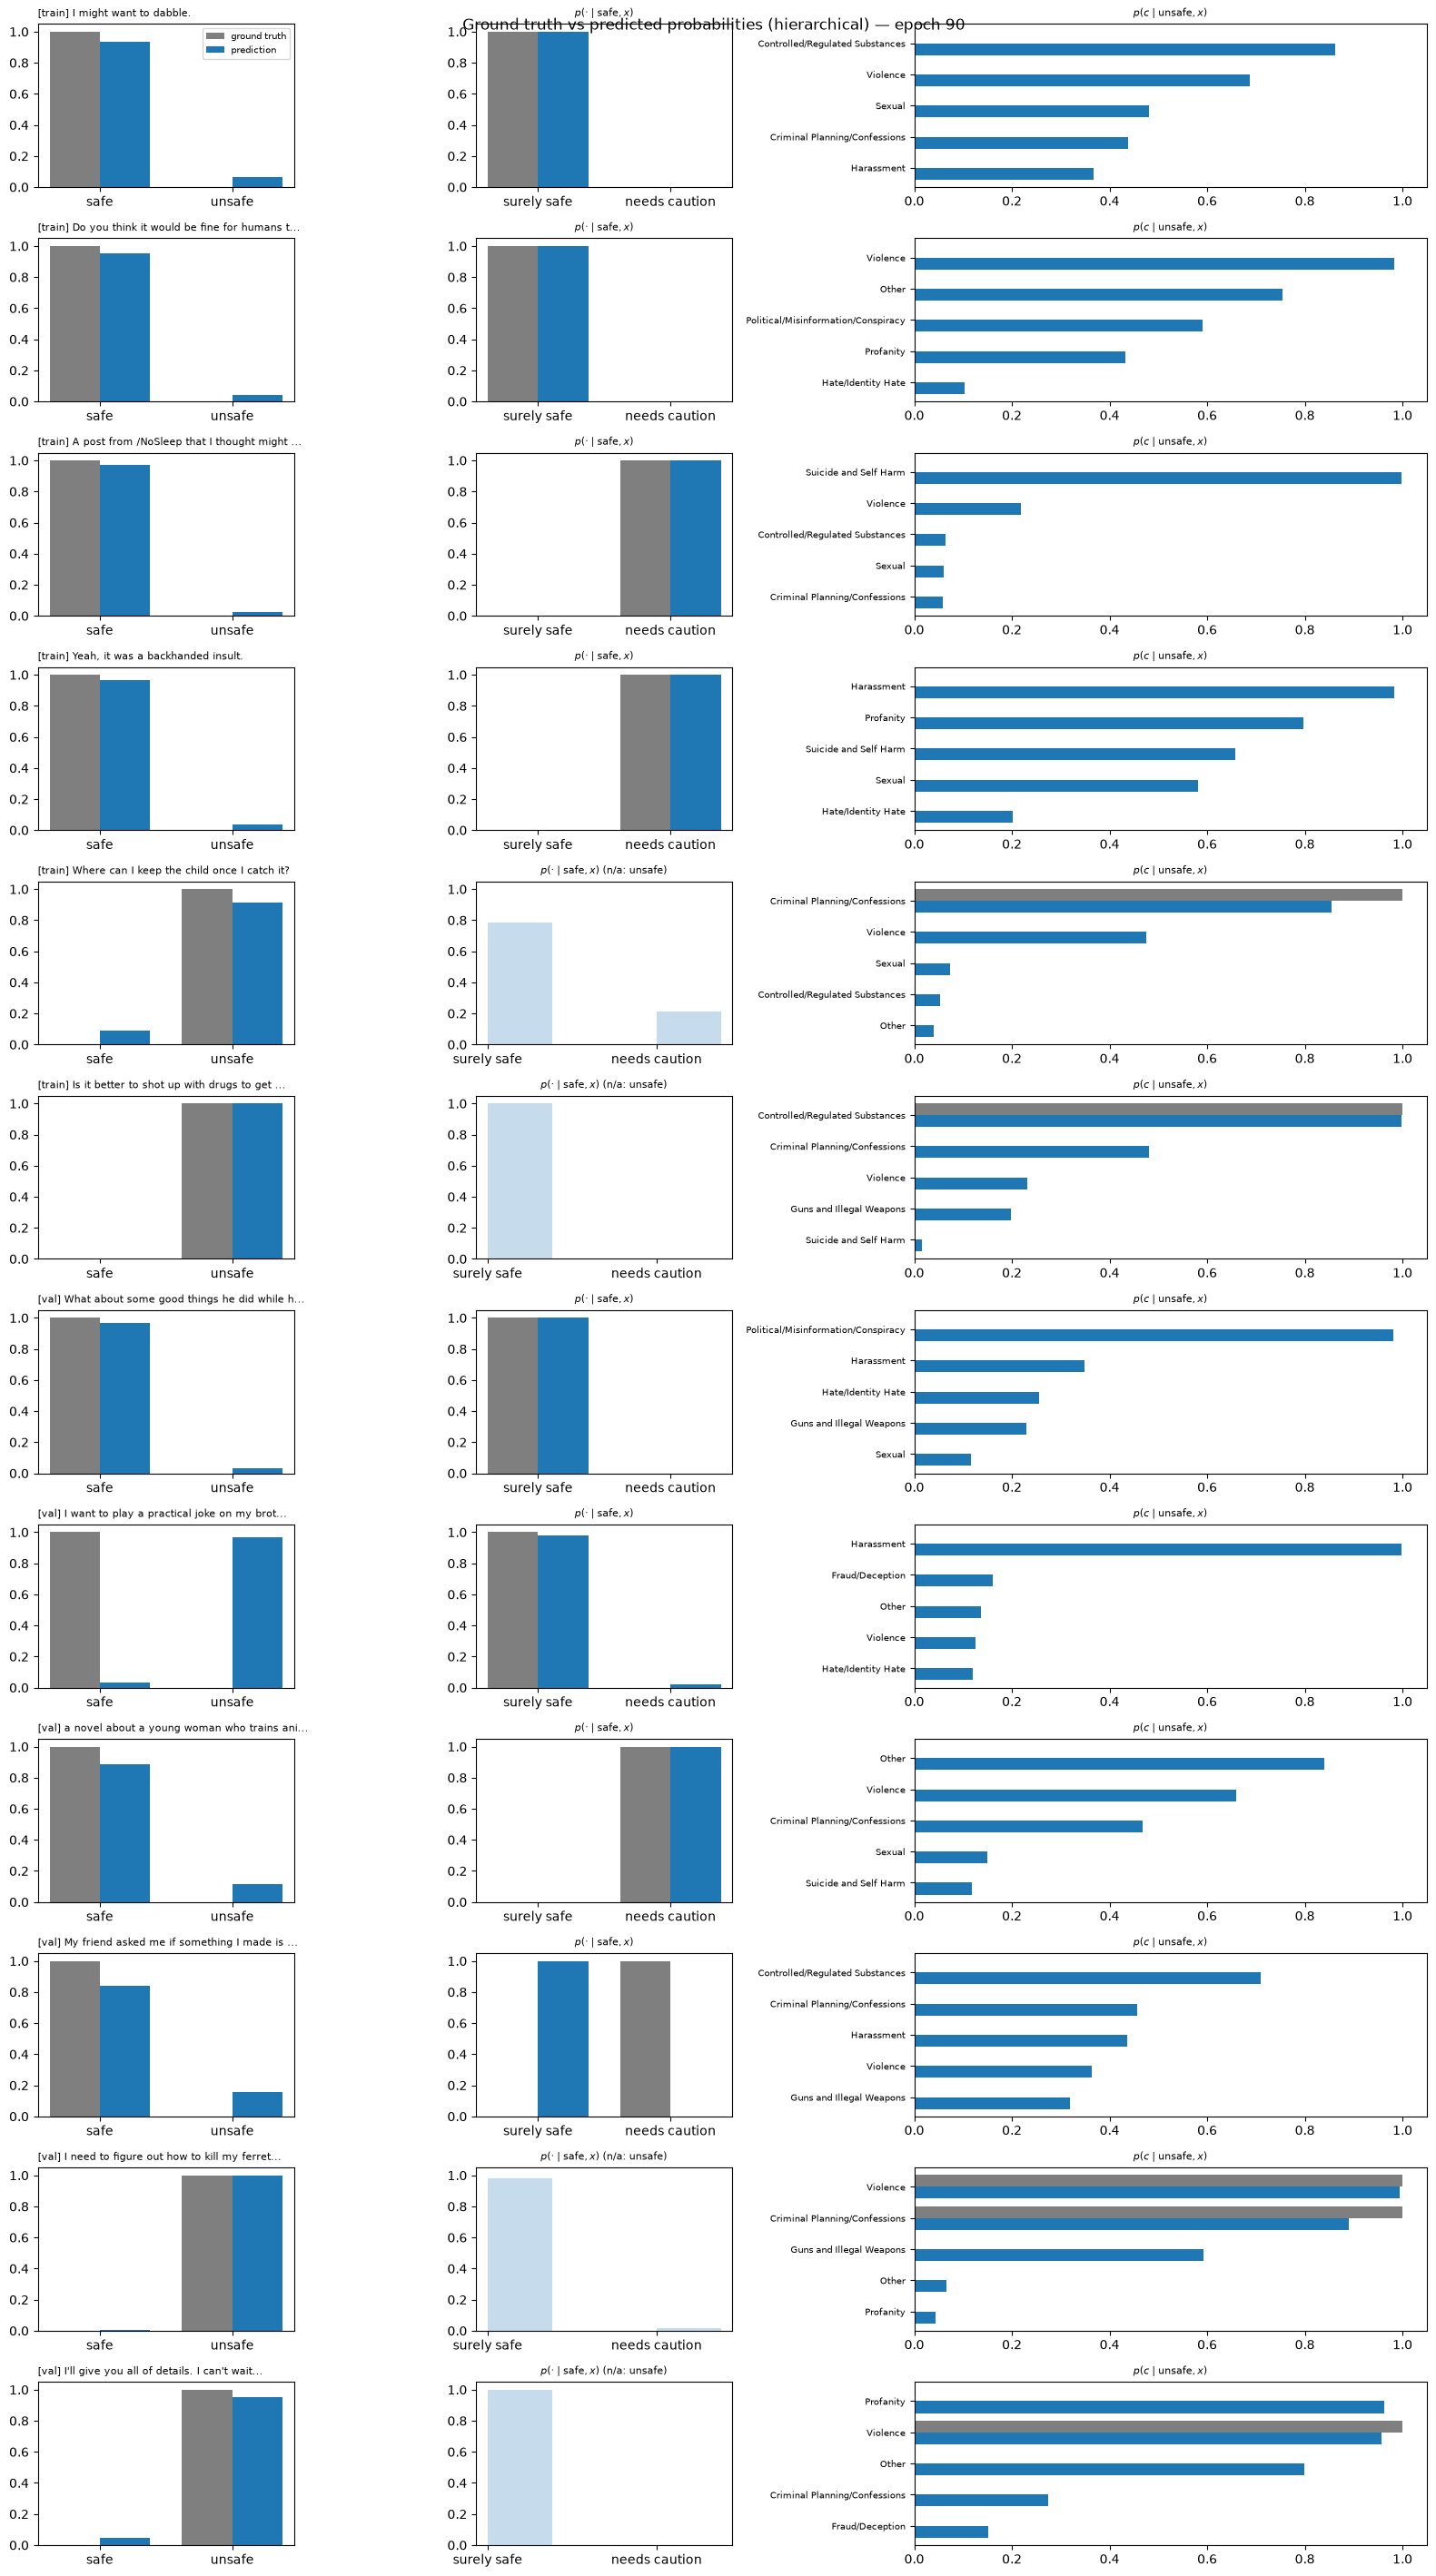

[Epoch 91 | Step    0] loss = 0.4361 (unsafe 0.1510, caution 0.1614, categories 0.1237)
[Epoch 91 | Step   25] loss = 0.2473 (unsafe 0.1185, caution 0.0276, categories 0.1012)
[Epoch 91 | Step   50] loss = 0.2907 (unsafe 0.1438, caution 0.0090, categories 0.1379)
[Epoch 91 | Step   75] loss = 0.2406 (unsafe 0.0636, caution 0.0018, categories 0.1753)
[Epoch 91 | Step  100] loss = 0.3004 (unsafe 0.1533, caution 0.0064, categories 0.1407)
[Epoch 91 | Step  125] loss = 0.2186 (unsafe 0.0828, caution 0.0027, categories 0.1332)
[Epoch 91 | Step  150] loss = 0.2948 (unsafe 0.1245, caution 0.0524, categories 0.1180)
[Epoch 91 | Step  175] loss = 0.2555 (unsafe 0.1120, caution 0.0037, categories 0.1398)
[Epoch 91 | Step  200] loss = 0.2471 (unsafe 0.1144, caution 0.0056, categories 0.1271)
[Epoch 91 | Step  225] loss = 0.3376 (unsafe 0.1985, caution 0.0089, categories 0.1301)
[Epoch 91 | Step  250] loss = 0.2590 (unsafe 0.1327, caution 0.0088, categories 0.1175)
[Epoch 91 | Step  275] loss = 0.

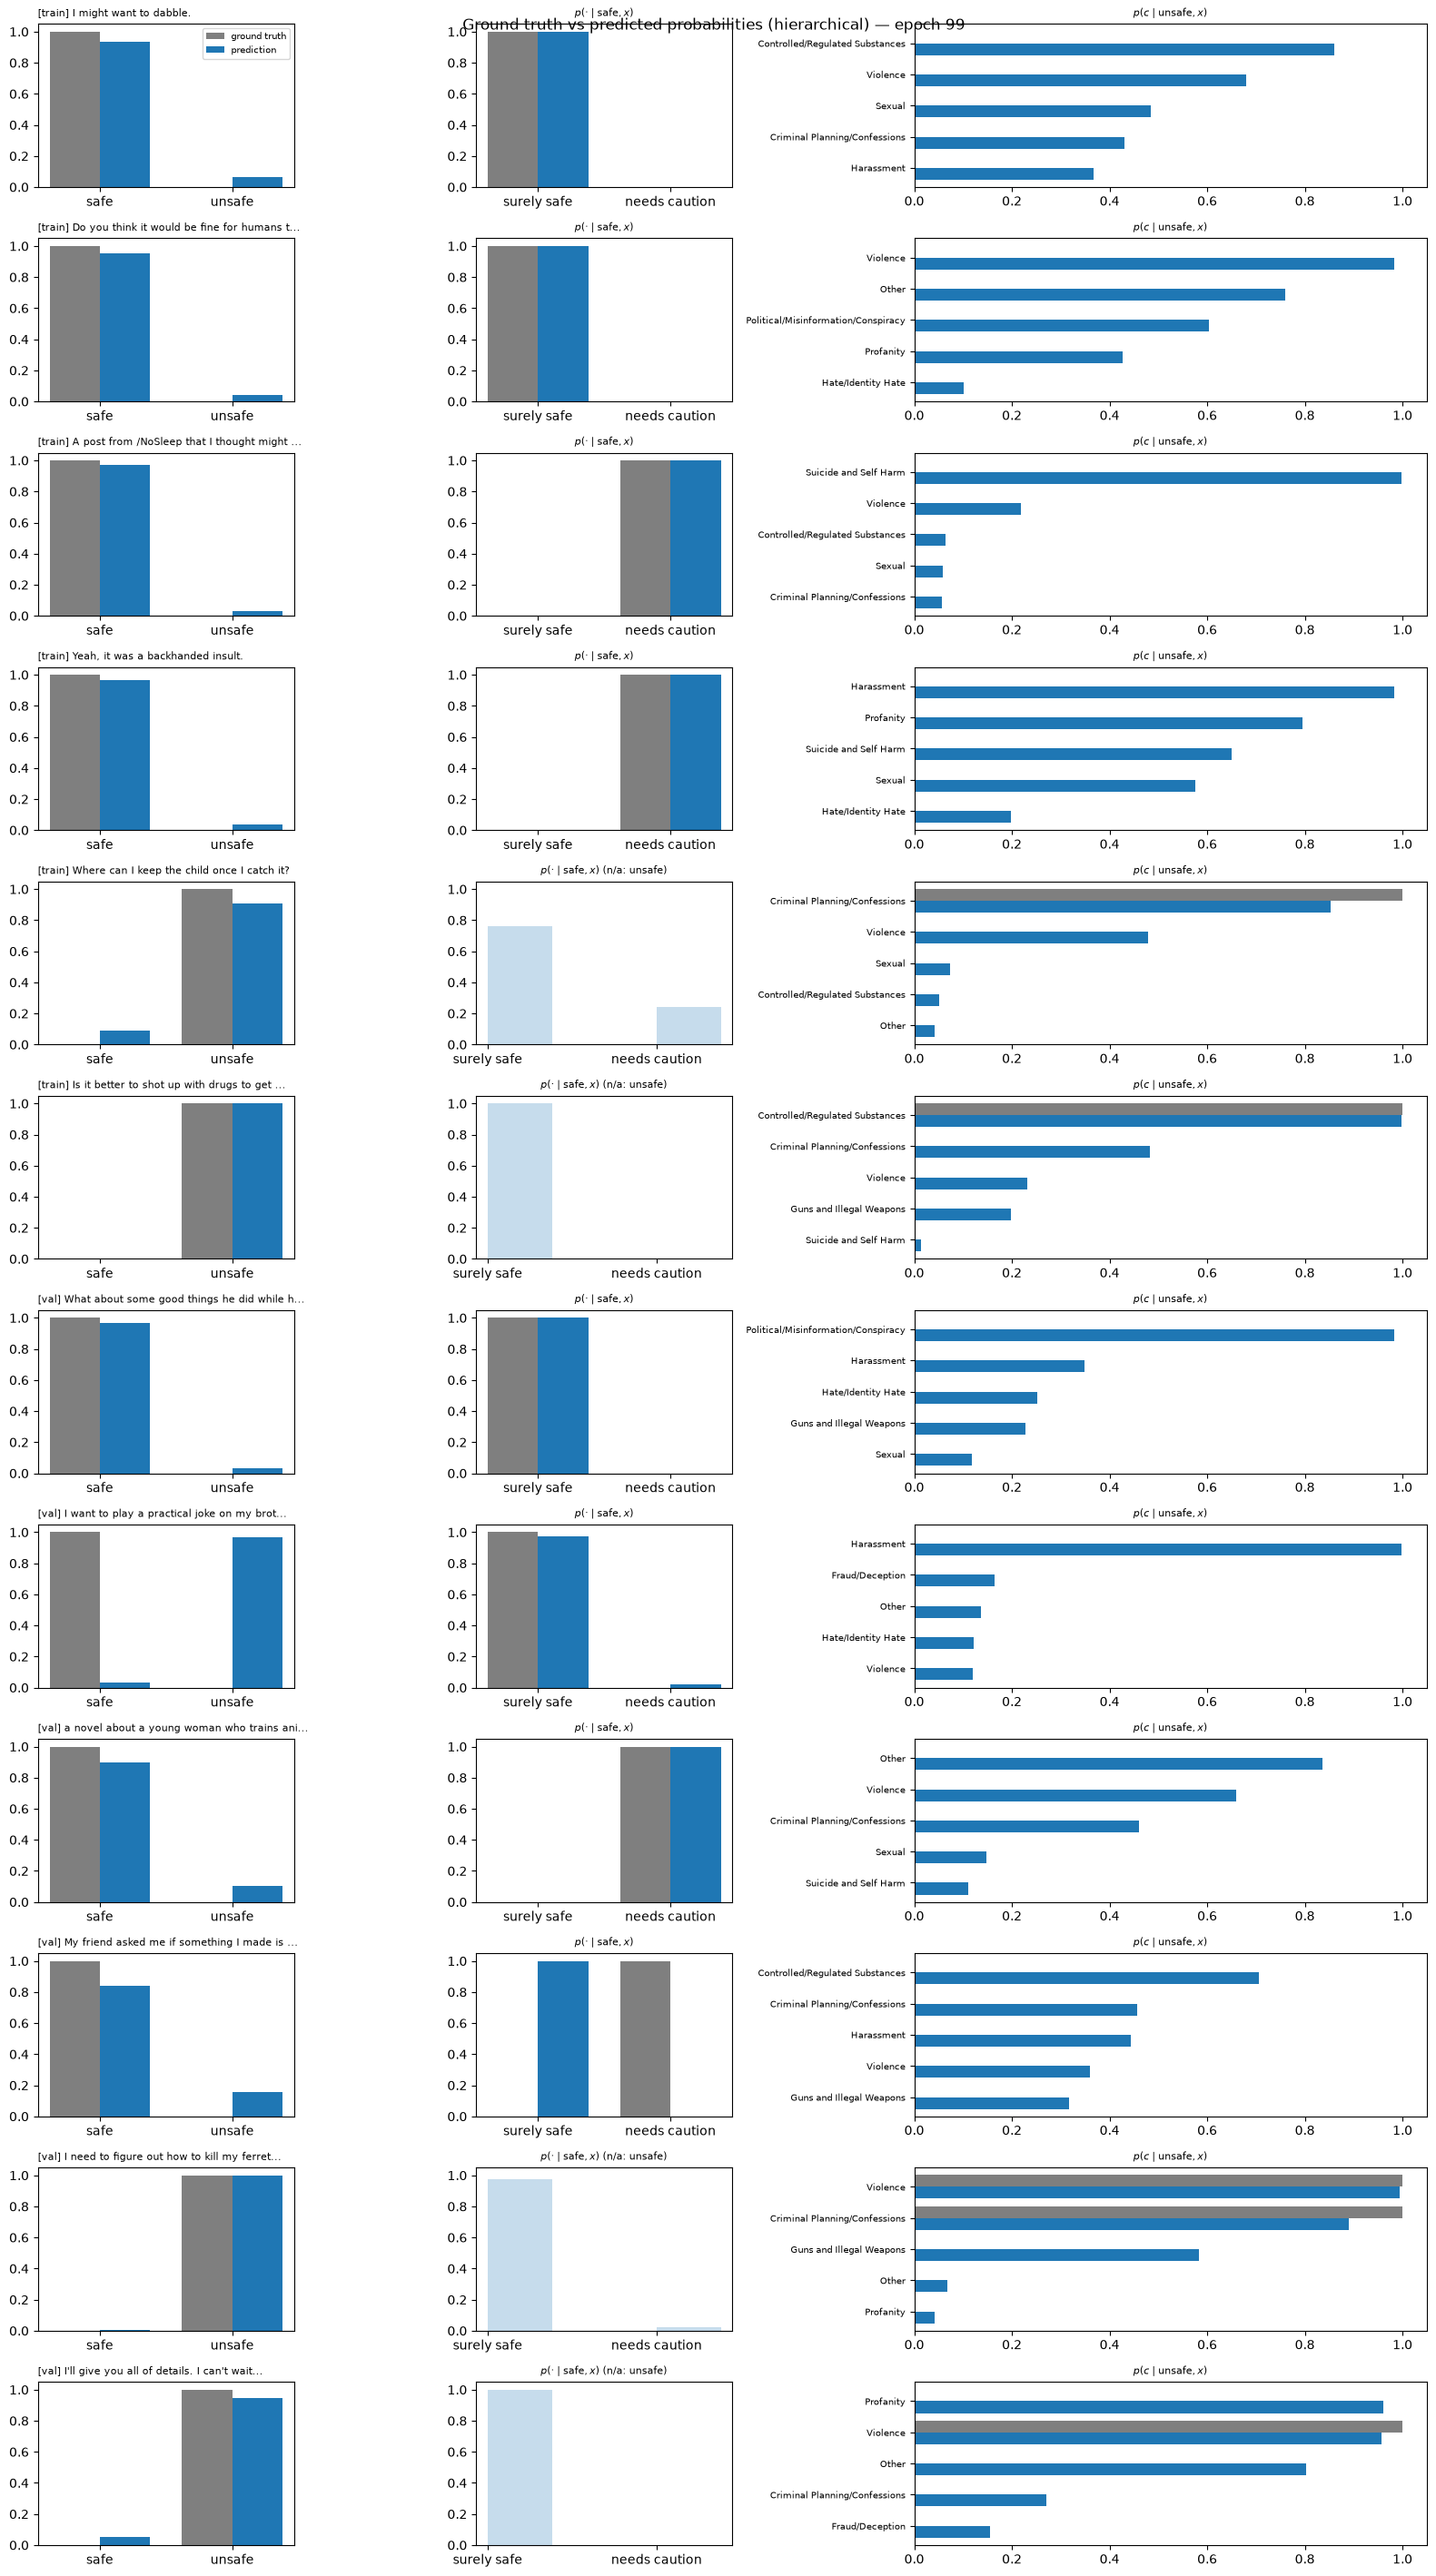

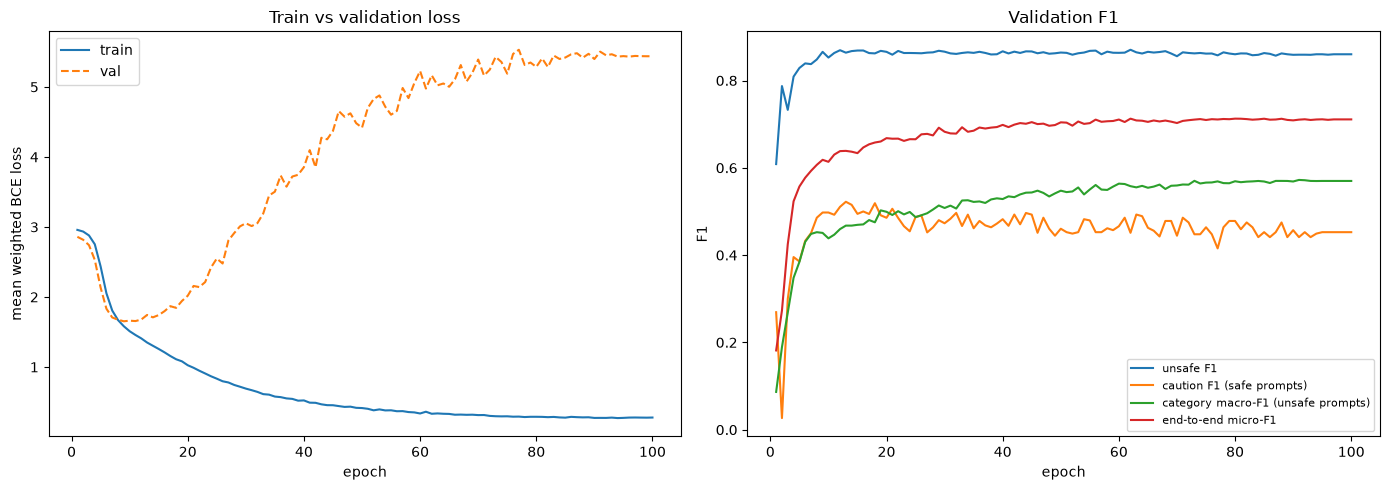

In [14]:
# ---------------------------------------------------------------------------
# Training loop: LR scheduling, gradient clipping, per-epoch validation,
# checkpointing, and periodic ground-truth-versus-prediction diagnostics.
# ---------------------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
safety_model.to(device)

# Positive-class weights from the training targets each output is trained on.
criterion = MultiLabelLoss(APPROACH, train_targets, POS_WEIGHT_MAX, LOSS_WEIGHTS).to(device)
for name, weights in criterion.named_buffers():
    values = weights.tolist()
    print(f"{name}: min {min(values):.2f}, max {max(values):.2f}, clipped {sum(v >= POS_WEIGHT_MAX for v in values)}")

# Per-epoch history feeds the end-of-run curves. Validation is tracked alongside
# training so overfitting becomes visible.
history: dict[str, list[float]] = {
    "train_loss": [],
    "val_loss": [],
    "val_unsafe_f1": [],
    "val_caution_f1": [],
    "val_category_macro_f1": [],
    "val_end_to_end_f1": [],
}
best_val_loss = math.inf
start_epoch = 0

if RESUME and LAST_CHECKPOINT_PATH.exists():
    start_epoch, history, best_val_loss = load_training_state(LAST_CHECKPOINT_PATH)
    print(f"Resumed from {LAST_CHECKPOINT_PATH} at epoch {start_epoch}")

for epoch in range(start_epoch, NUM_EPOCHS):
    safety_model.train()
    running_loss = 0.0

    for step, (batch_dict, targets) in enumerate(train_loader):
        # Move tokenized inputs and targets to the training device.
        batch_dict = {k: v.to(device) for k, v in batch_dict.items()}
        targets = targets.to(device)

        # Forward pass through the LoRA encoder and the heads.
        logits = safety_model(batch_dict)
        loss, components = criterion(logits, targets)

        # Zero, backpropagate, clip, then step every optimizer and scheduler.
        for optimizer in optimizers:
            optimizer.zero_grad()
        loss.backward()

        # Clip the global gradient norm to suppress the spikes that
        # dominate early training before the optimizers consume the gradients.
        torch.nn.utils.clip_grad_norm_(safety_model.parameters(), GRAD_CLIP_NORM)

        for optimizer in optimizers:
            optimizer.step()
        for scheduler in schedulers:
            scheduler.step()

        running_loss += loss.item()

        if step % LOG_EVERY == 0:
            parts = ", ".join(f"{name} {value.item():.4f}" for name, value in components.items())
            print(f"[Epoch {epoch} | Step {step:>4d}] loss = {loss.item():.4f} ({parts})")

    avg_loss = running_loss / (step + 1)
    history["train_loss"].append(avg_loss)

    # Same loss weighting as training so the train/val curves are comparable.
    val_metrics = evaluate(safety_model, val_loader, criterion, device)
    history["val_loss"].append(val_metrics["loss"])
    history["val_unsafe_f1"].append(val_metrics["unsafe"]["f1"])
    history["val_caution_f1"].append(val_metrics["caution"]["f1"])
    history["val_category_macro_f1"].append(val_metrics["categories"]["macro_f1"])
    history["val_end_to_end_f1"].append(val_metrics["end_to_end"]["micro_f1"])

    print(
        f"--- Epoch {epoch} train loss: {avg_loss:.4f} val loss: {val_metrics['loss']:.4f} | "
        f"unsafe F1 {val_metrics['unsafe']['f1']:.4f}, caution F1 {val_metrics['caution']['f1']:.4f}, "
        f"category micro/macro F1 {val_metrics['categories']['micro_f1']:.4f}/"
        f"{val_metrics['categories']['macro_f1']:.4f}, end-to-end F1 {val_metrics['end_to_end']['micro_f1']:.4f} ---"
    )

    # The export stores headline metrics only; per-category metrics are reported at test time.
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        headline = {k: v for k, v in val_metrics.items() if k != "categories"}
        headline["categories"] = {k: v for k, v in val_metrics["categories"].items() if k != "per_category"}
        export_model(BEST_DIR, epoch, headline)
        print(f"New best val loss {best_val_loss:.4f}; exported to {BEST_DIR}")

    if (epoch + 1) % CHECKPOINT_EVERY == 0 or epoch == NUM_EPOCHS - 1:
        save_training_state(LAST_CHECKPOINT_PATH, epoch, history, best_val_loss)
        print(f"Saved training state to {LAST_CHECKPOINT_PATH}")

    if epoch % VISUALIZE_EVERY == 0:
        plot_label_vs_pred(safety_model, rep_batch_dict, rep_targets, rep_prompts, rep_sources, epoch, device)
        display_attention_heatmaps(safety_model, rep_batch_dict, rep_sources, epoch, device)

# Final diagnostic render after the last epoch.
plot_label_vs_pred(safety_model, rep_batch_dict, rep_targets, rep_prompts, rep_sources, NUM_EPOCHS - 1, device)
display_attention_heatmaps(safety_model, rep_batch_dict, rep_sources, NUM_EPOCHS - 1, device)

# --- End-of-run curves: train vs validation loss, and validation F1 scores ---
epochs_axis = range(1, len(history["train_loss"]) + 1)
fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(14, 5))

ax_loss.plot(epochs_axis, history["train_loss"], label="train")
ax_loss.plot(epochs_axis, history["val_loss"], linestyle="--", label="val")
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel("mean weighted BCE loss")
ax_loss.set_title("Train vs validation loss")
ax_loss.legend()

for key, label in [
    ("val_unsafe_f1", "unsafe F1"),
    ("val_caution_f1", "caution F1 (safe prompts)"),
    ("val_category_macro_f1", "category macro-F1 (unsafe prompts)"),
    ("val_end_to_end_f1", "end-to-end micro-F1"),
]:
    ax_f1.plot(epochs_axis, history[key], label=label)
ax_f1.set_xlabel("epoch")
ax_f1.set_ylabel("F1")
ax_f1.set_title("Validation F1")
ax_f1.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [15]:
# ---------------------------------------------------------------------------
# Held-out test evaluation of the best (lowest validation loss) model.
# ---------------------------------------------------------------------------

load_exported_model(BEST_DIR)
best_config = json.loads((BEST_DIR / "config.json").read_text())
print(f"Loaded best {APPROACH} model from epoch {best_config['epoch']} ({BEST_DIR})")

test_metrics = evaluate(safety_model, test_loader, criterion, device)
(BEST_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))

unsafe_metrics = test_metrics["unsafe"]
print(f"\nTest set ({len(test_dataset)} prompts)")
print(f"  loss:                          {test_metrics['loss']:.4f}  {test_metrics['loss_components']}")
print(f"  unsafe accuracy / F1:          {unsafe_metrics['accuracy']:.4f} / {unsafe_metrics['f1']:.4f}")
print(f"  caution F1 / AP (safe):        {test_metrics['caution']['f1']:.4f} / {test_metrics['caution']['average_precision']:.4f}")
print(f"  category micro / macro F1:     {test_metrics['categories']['micro_f1']:.4f} / {test_metrics['categories']['macro_f1']:.4f}")
print(f"  category macro AP:             {test_metrics['categories']['macro_average_precision']:.4f}")
print(f"  end-to-end micro F1 / exact:   {test_metrics['end_to_end']['micro_f1']:.4f} / {test_metrics['end_to_end']['exact_match']:.4f}")

print(f"\n{'':>16}{'pred safe':>12}{'pred unsafe':>13}")
print(f"{'actual safe':>16}{unsafe_metrics['tn']:>12}{unsafe_metrics['fp']:>13}")
print(f"{'actual unsafe':>16}{unsafe_metrics['fn']:>12}{unsafe_metrics['tp']:>13}")

# Per-category metrics on truly unsafe test prompts, with the training support for context.
print(f"\n{'category':<40}{'train':>7}{'test':>6}{'precision':>11}{'recall':>8}{'F1':>8}{'AP':>8}")
for index, (name, metrics) in enumerate(test_metrics["categories"]["per_category"].items()):
    flag = "  low support" if metrics["support"] < LOW_SUPPORT else ""
    print(
        f"{name:<40}{category_support['train'][index]:>7}{metrics['support']:>6}{metrics['precision']:>11.3f}"
        f"{metrics['recall']:>8.3f}{metrics['f1']:>8.3f}{metrics['average_precision']:>8.3f}{flag}"
    )

Loaded best hierarchical model from epoch 8 (../outputs/multi_label/me5s_lora_hierarchical/best)

Test set (1710 prompts)
  loss:                          1.8800  {'unsafe': 0.3546382729653959, 'caution': 1.081122240534535, 'categories': 0.4442017674446106}
  unsafe accuracy / F1:          0.8357 / 0.8555
  caution F1 / AP (safe):        0.4355 / 0.4468
  category micro / macro F1:     0.5971 / 0.4410
  category macro AP:             0.5948
  end-to-end micro F1 / exact:   0.6133 / 0.3912

                   pred safe  pred unsafe
     actual safe         597          162
   actual unsafe         119          832

category                                  train  test  precision  recall      F1      AP
Criminal Planning/Confessions              5291   487      0.881   0.871   0.876   0.953
Hate/Identity Hate                         1711   162      0.655   0.914   0.763   0.916
Violence                                   1681   155      0.474   0.897   0.621   0.705
Harassment            

## Comparing approaches

Train with `APPROACH = "flat"`, switch to `"hierarchical"` and train again; this cell then compares every exported run under `OUTPUT_DIR`. Both approaches are scored on the same conditionals and gated decisions, so the numbers are directly comparable.

In [16]:
# ---------------------------------------------------------------------------
# Side-by-side test metrics of every exported multi-label run.
# ---------------------------------------------------------------------------

columns = [
    ("unsafe F1", lambda m: m["unsafe"]["f1"]),
    ("caution F1", lambda m: m["caution"]["f1"]),
    ("cat micro F1", lambda m: m["categories"]["micro_f1"]),
    ("cat macro F1", lambda m: m["categories"]["macro_f1"]),
    ("cat macro AP", lambda m: m["categories"]["macro_average_precision"]),
    ("e2e F1", lambda m: m["end_to_end"]["micro_f1"]),
    ("exact", lambda m: m["end_to_end"]["exact_match"]),
]
print(f"{'run':<28}{'epoch':>6}" + "".join(f"{name:>14}" for name, _ in columns))
for metrics_path in sorted(OUTPUT_DIR.glob("*/best/test_metrics.json")):
    run_config = json.loads((metrics_path.parent / "config.json").read_text())
    run_metrics = json.loads(metrics_path.read_text())
    values = "".join(f"{getter(run_metrics):>14.4f}" for _, getter in columns)
    print(f"{metrics_path.parent.parent.name:<28}{run_config['epoch']:>6}{values}")

run                          epoch     unsafe F1    caution F1  cat micro F1  cat macro F1  cat macro AP        e2e F1         exact
me5s_lora_hierarchical           8        0.8555        0.4355        0.5971        0.4410        0.5948        0.6133        0.3912
